# VDUI Unit 4 - PPT 5 Activity

**Student Name:** A Sheiman Joshi  
**SRN:** PES2UG24CS003  
**Section:** Section A  
**Subject:** Visual Design and User Interface (UE24CS342AA9)  
**Unit:** Unit 4 - AI-Assisted and Advanced Visualization  


# Demo: Visualizing ML Predictions, Probability and Uncertainty

**Unit 4 · AI-Assisted and Advanced Visualization · Lecture 5**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

This notebook walks through every topic of the lecture with **two synthetic problems** plus a few small synthetic series. It needs no internet and **no API key**.

* **Classification:** a 3-class image classifier (*Cat, Dog, Bird*). We train a small model (Gaussian Naive Bayes on correlated features) that is known to be **overconfident**, so the calibration tools have something to find. It is trained on **phone-camera** images only, but in use it also sees noisier **trail-camera** images.
* **Regression:** daily **electricity demand** (MWh) predicted from the day's temperature. A too-simple model and a proper one let us compare prediction views, intervals and bands.

| Section | Lecture topic |
|---|---|
| 1 | ML outputs and typical views |
| 2 | Predictions and predicted values (predicted vs actual) |
| 3–5 | Class probabilities; confidence measures; confidence vs probability |
| 6–7 | Prediction intervals vs confidence bands; where intervals come from |
| 8–12 | SD, SE, CIs; error bars (and misreading them); graded bars; bands; graded forecast bands; hypothetical outcome plots |
| 13–14 | Distributions, ECDFs, Q-Q plots; quantile dotplots and frequency framing |
| 15–18 | Calibration: reliability diagrams, ECE, Brier, temperature scaling, calibration by class and group |
| 19–21 | Confusion matrices, performance summaries, ROC / PR curves, choosing an operating point |
| 22–25 | Uncertainty in AI models: aleatoric vs epistemic, extrapolation, Bayesian posteriors, prediction sets |
| 26–27 | Communicating uncertainty without misleading: audience, attention, colour, salience |
| 28–29 | Comparing confidence with correctness: abstention, high-confidence errors; a model performance view |
| 30 | Numericals 1–5 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp
from sklearn.datasets import make_classification
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import PolynomialFeatures

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE, LIGHT = "#bdbdbd", "#d95f02", "#4c78a8", "#e6e6e6"
CLASSES = ["Cat", "Dog", "Bird"]

## 1 · Visualization of ML outputs

A trained model returns more than an answer. The central design question of the lecture: **how do we show not just what the model predicts, but how sure it is, and how often that sureness is justified?** (Wilke Ch. 16: uncertainty is part of the data.)

| Output | Example | Typical view |
|---|---|---|
| Class label | "Dog" | counts, confusion matrix |
| Class probabilities | 0.70 / 0.20 / 0.10 | bar chart per case, probability heatmap |
| Score | anomaly score 0.83 | histogram of scores, ranked list |
| Numeric prediction | 42.1 | predicted-vs-actual scatterplot |
| Interval | 38 to 47 | error bar, confidence or prediction band |
| Prediction set | {Cat, Dog} | list of plausible classes |

In [2]:
Xc, yc = make_classification(n_samples=9000, n_features=8, n_informative=4, n_redundant=4, n_classes=3, n_clusters_per_class=1,
                             weights=[.45, .40, .15], class_sep=1.1, flip_y=0.02, random_state=7)
grp = np.where(np.random.default_rng(7).random(len(yc)) < 0.7, "phone camera", "trail camera")
Xc[grp == "trail camera"] += np.random.default_rng(8).normal(0, 0.9, Xc[grp == "trail camera"].shape)   # noisier images
X_tr, X_rest, y_tr, y_rest, g_tr, g_rest = train_test_split(Xc, yc, grp, train_size=4000, random_state=0, stratify=yc)
X_cal, X_te, y_cal, y_te, g_cal, g_te = train_test_split(X_rest, y_rest, g_rest, train_size=2000, random_state=0, stratify=y_rest)
phone = g_tr == "phone camera"
X_tr, y_tr, g_tr = X_tr[phone], y_tr[phone], g_tr[phone]          # the model only ever saw phone-camera images
nb = GaussianNB().fit(X_tr, y_tr)
logit_cal, logit_te = nb.predict_joint_log_proba(X_cal), nb.predict_joint_log_proba(X_te)   # un-normalised log-probabilities
P = softmax(logit_te, axis=1)
pred, conf = P.argmax(1), P.max(axis=1)
te = pd.DataFrame(P, columns=[f"p_{c}" for c in CLASSES]).assign(true=np.array(CLASSES)[y_te], pred=np.array(CLASSES)[pred],
                                                               confidence=conf, correct=pred == y_te, source=g_te)
print(f"train {len(y_tr)} | calibration {len(y_cal)} | test {len(y_te)} | test accuracy {te.correct.mean():.3f} | mean confidence {te.confidence.mean():.3f}")
te.head()

train 2796 | calibration 2000 | test 3000 | test accuracy 0.862 | mean confidence 0.950


,p_Cat,p_Dog,p_Bird,true,pred,confidence,correct,source
0,5.106023e-20,1.000000e+00,1.859381e-23,Dog,Dog,1.000000,True,phone camera
1,9.995403e-01,1.490687e-09,4.596954e-04,Cat,Cat,0.999540,True,trail camera
2,9.998724e-01,4.279683e-10,1.275657e-04,Cat,Cat,0.999872,True,trail camera
3,8.905790e-04,3.214841e-12,9.991094e-01,Bird,Bird,0.999109,True,phone camera
4,9.972219e-01,3.850624e-11,2.778127e-03,Cat,Cat,0.997222,True,trail camera


In [3]:
rs = np.random.default_rng(3)
temp_c = np.r_[rs.uniform(8, 20, 260), rs.uniform(24, 36, 260)]          # a mild-weather gap (20-24 °C) in the training years
demand = 520 + 1.9 * (temp_c - 21) ** 2 + rs.normal(0, 28, len(temp_c))  # heating below ~21 °C, cooling above
en = pd.DataFrame({"temp_c": temp_c, "demand": demand})
en_tr, en_te = train_test_split(en, test_size=0.3, random_state=1)
lin = LinearRegression().fit(en_tr[["temp_c"]], en_tr.demand)                                   # too simple
poly = PolynomialFeatures(2); quad = LinearRegression().fit(poly.fit_transform(en_tr[["temp_c"]]), en_tr.demand)
en_te = en_te.assign(pred_linear=lin.predict(en_te[["temp_c"]]), pred_quadratic=quad.predict(poly.transform(en_te[["temp_c"]])))
en_te.head()

,temp_c,demand,pred_linear,pred_quadratic
273,29.985761,693.032143,693.761511,671.744094
272,34.929003,892.178119,716.280055,890.551401
329,34.027909,861.085985,712.175196,843.618591
480,31.783000,767.194775,701.948689,740.357895
173,11.181862,693.919977,608.101840,703.330623


## 2 · Predictions and predicted values (Wilke Ch. 12 paired data, Ch. 14 trends)

Plot **predicted against actual**: points on the diagonal are perfect predictions. A reference diagonal makes systematic deviation visible; a **smooth trend** through the points reveals bias. Keep both axes on the same scale.

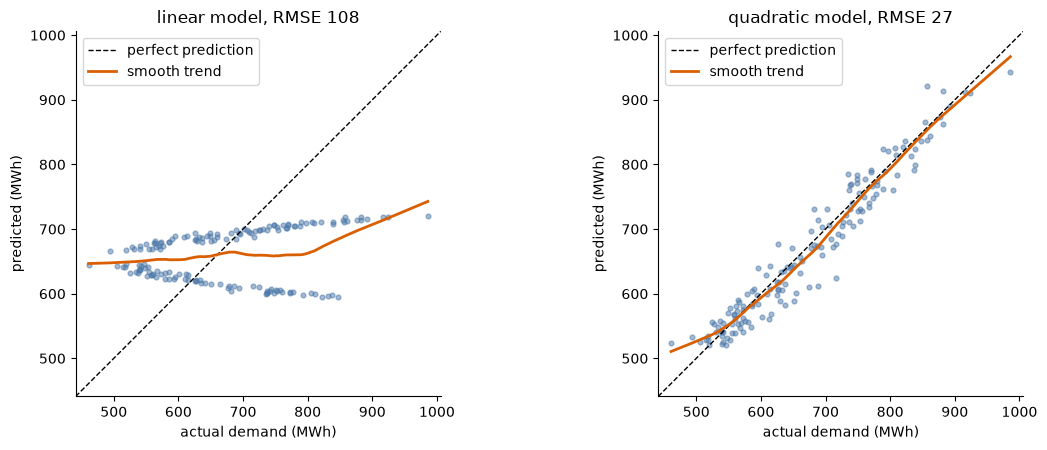

Linear model: over-predicts low-demand days and under-predicts high-demand days (the trend is flatter than the diagonal).


In [4]:
def lowess(x, y, frac=0.35):
    o = np.argsort(x); x, y = np.asarray(x)[o], np.asarray(y)[o]
    k = int(frac * len(x)); out = np.empty(len(x))
    for i in range(len(x)):
        d = np.abs(x - x[i]); nb_ = np.argsort(d)[:k]; w = (1 - (d[nb_] / (d[nb_].max() + 1e-9)) ** 3) ** 3
        A = np.c_[np.ones(k), x[nb_]]; out[i] = (np.r_[1, x[i]] @ np.linalg.lstsq(A * w[:, None] ** .5, y[nb_] * w ** .5, rcond=None)[0])
    return x, out

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a_, col in zip(ax, ["pred_linear", "pred_quadratic"]):
    a_.scatter(en_te.demand, en_te[col], s=12, alpha=.5, color=BLUE)
    lim = [en_te.demand.min() - 20, en_te.demand.max() + 20]
    a_.plot(lim, lim, "--", color="k", lw=1, label="perfect prediction"); a_.plot(*lowess(en_te.demand, en_te[col]), color=ACCENT, lw=2, label="smooth trend")
    rmse = np.sqrt(((en_te.demand - en_te[col]) ** 2).mean())
    a_.set_xlim(lim); a_.set_ylim(lim); a_.set_aspect("equal"); a_.set_xlabel("actual demand (MWh)"); a_.set_ylabel("predicted (MWh)")
    a_.set_title(f"{col.split('_')[1]} model, RMSE {rmse:.0f}"); a_.legend(loc="upper left")
plt.tight_layout(); plt.show()
print("Linear model: over-predicts low-demand days and under-predicts high-demand days (the trend is flatter than the diagonal).")

## 3 · Class probabilities

A classifier returns one probability per class (they sum to 1). **The top-1 label hides the margin:** a near-tie and a confident call look identical. Show the probability vector (bars use *length*, the accurate channel, Ware G5.15), or at least the top-k and the margin.

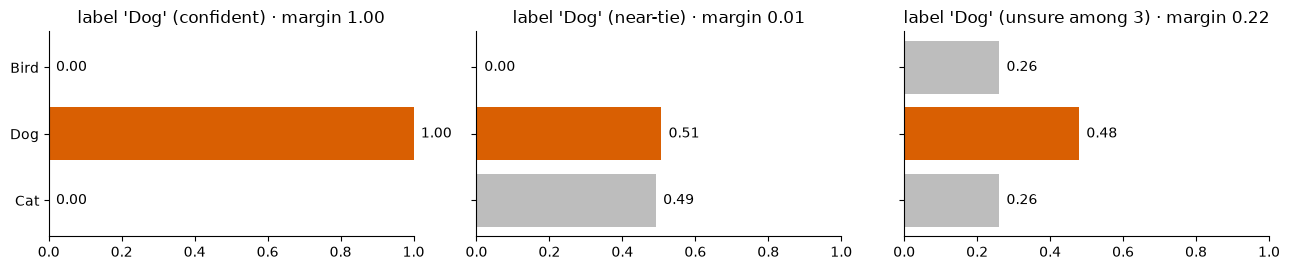

In [5]:
dogs = te[te.pred == "Dog"]
pv = dogs[["p_Cat", "p_Dog", "p_Bird"]]
picks = {"confident": dogs.confidence.idxmax(),
         "near-tie": (pv.p_Dog - pv[["p_Cat", "p_Bird"]].max(axis=1)).idxmin(),
         "unsure among 3": (-(pv * np.log(pv + 1e-12)).sum(axis=1)).idxmax()}
fig, ax = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
for a_, (lab, i) in zip(ax, picks.items()):
    p = te.loc[i, ["p_Cat", "p_Dog", "p_Bird"]].values.astype(float)
    a_.barh(CLASSES, p, color=[ACCENT if c == "Dog" else GREY for c in CLASSES]); a_.set_xlim(0, 1)
    for k_, v in enumerate(p): a_.text(v + .02, k_, f"{v:.2f}", va="center")
    s_ = np.sort(p)[::-1]; a_.set_title(f"label 'Dog' ({lab}) · margin {s_[0] - s_[1]:.2f}")
plt.tight_layout(); plt.show()

### Many cases: a probability heatmap
Rows = cases, columns = classes (fixed order). **Sort by margin** so uncertain predictions gather together. Shading cannot give exact values (Ware G3.1), so print numbers where they matter.

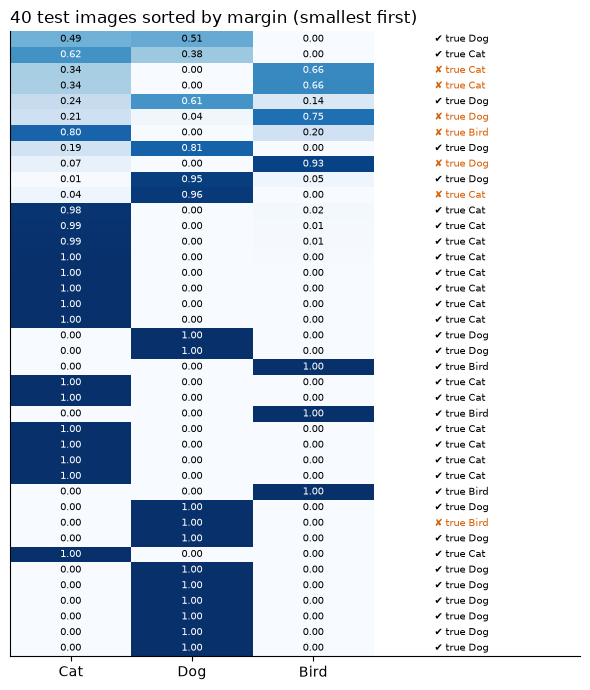

In [6]:
s50 = te.sample(40, random_state=2).copy()
srt = np.sort(s50[["p_Cat", "p_Dog", "p_Bird"]].values, axis=1)
s50["margin"] = srt[:, -1] - srt[:, -2]
s50 = s50.sort_values("margin")
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(s50[["p_Cat", "p_Dog", "p_Bird"]].values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for r_ in range(len(s50)):
    for c_ in range(3): ax.text(c_, r_, f"{s50.iloc[r_, c_]:.2f}", ha="center", va="center", fontsize=7, color="w" if s50.iloc[r_, c_] > .6 else "k")
    ax.text(3.0, r_, ("✔" if s50.correct.iloc[r_] else "✘") + f" true {s50.true.iloc[r_]}", va="center", fontsize=7, color="k" if s50.correct.iloc[r_] else ACCENT)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks([]); ax.set_xlim(-.5, 4.2)
ax.set_title("40 test images sorted by margin (smallest first)", loc="left"); plt.tight_layout(); plt.show()

## 4 · Confidence scores and measures

| Measure | How it is obtained | How to read it |
|---|---|---|
| Max class probability | highest softmax output | higher = more confident; **not necessarily calibrated** |
| Margin | top minus second probability | small = near-tie |
| Entropy | spread of the whole vector | high = unsure among many classes |
| Ensemble agreement | share of models voting for the label | low = model uncertainty |
| Interval width | upper − lower bound | wide = imprecise numeric prediction |

,pred,true,confidence,margin,entropy,agreement
confident,Dog,Dog,1.00,1.00,-0.00,1.00
near-tie,Dog,Dog,0.51,0.01,0.64,0.56
unsure among 3,Dog,Dog,0.48,0.22,0.96,1.00


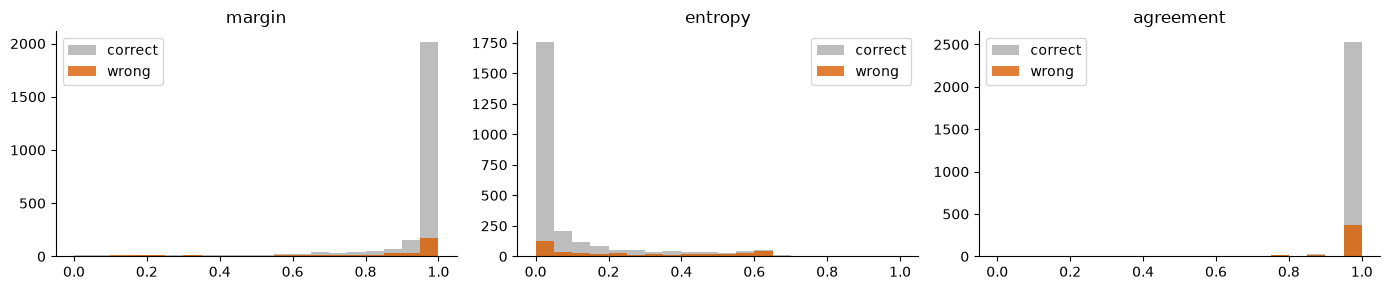

In [7]:
ens = [GaussianNB().fit(*(lambda i: (X_tr[i], y_tr[i]))(np.random.default_rng(s_).integers(0, len(y_tr), len(y_tr)))) for s_ in range(9)]
votes = np.array([m_.predict(X_te) for m_ in ens])
te["agreement"] = (votes == pred).mean(0)
te["margin"] = np.sort(P, 1)[:, -1] - np.sort(P, 1)[:, -2]
te["entropy"] = -(P * np.log(P + 1e-12)).sum(axis=1) / np.log(3)
display(te.loc[list(picks.values()), ["pred", "true", "confidence", "margin", "entropy", "agreement"]].round(2).set_axis(list(picks), axis=0))
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a_, m_ in zip(ax, ["margin", "entropy", "agreement"]):
    bins = np.linspace(0, 1, 21)
    a_.hist(te.loc[te.correct, m_], bins=bins, color=GREY, label="correct"); a_.hist(te.loc[~te.correct, m_], bins=bins, color=ACCENT, alpha=.8, label="wrong")
    a_.set_title(m_); a_.legend()
plt.tight_layout(); plt.show()

## 5 · Confidence versus probability

A **probability** is a testable claim: among cases given 0.8, about 80% should be correct. A **confidence score** need not satisfy this; modern networks are often overconfident (Guo et al. 2017). Statistics adds a third meaning: a 95% *confidence interval* describes a procedure over repeated samples, whereas a Bayesian *credible interval* states a probability about the parameter (Wilke Ch. 16). **Label what a number means, and check it against outcomes.**

In [8]:
for lo_, hi_ in [(.5, .7), (.7, .9), (.9, .99), (.99, 1.01)]:
    m_ = te.confidence.between(lo_, hi_, inclusive="left")
    print(f"confidence {lo_:.2f}–{min(hi_, 1):.2f}: {m_.sum():4d} images, mean confidence {te.confidence[m_].mean():.3f}, actually correct {te.correct[m_].mean():.3f}")

confidence 0.50–0.70:  166 images, mean confidence 0.606, actually correct 0.566
confidence 0.70–0.90:  295 images, mean confidence 0.818, actually correct 0.681
confidence 0.90–0.99:  606 images, mean confidence 0.962, actually correct 0.815
confidence 0.99–1.00: 1926 images, mean confidence 0.999, actually correct 0.931


## 6 · Prediction intervals vs confidence bands

The **confidence band** shows the uncertainty of the **average** prediction. A new case also carries its own noise, so its **prediction interval** is wider. To judge individual predictions, show the prediction interval. (Wilke Ch. 14, 16; standard regression theory.)

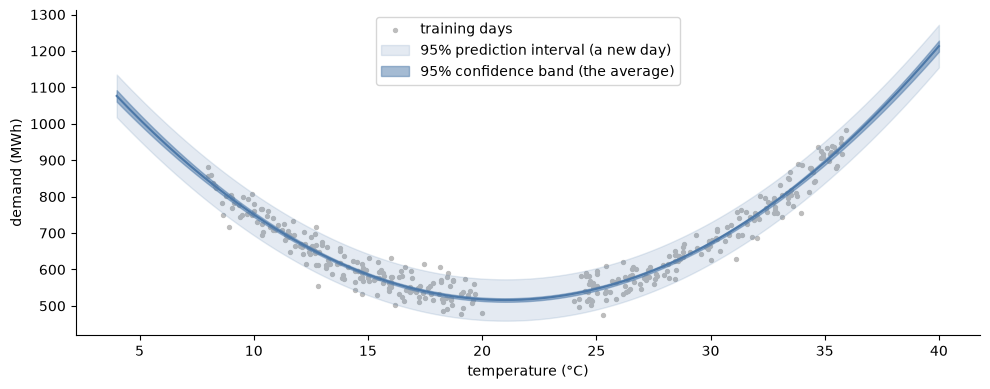

Share of NEW test days inside the confidence band: 13% | inside the prediction interval: 96% (target 95%)


In [9]:
Xq_tr = poly.transform(en_tr[["temp_c"]]); resid = en_tr.demand - quad.predict(Xq_tr)
s2 = (resid ** 2).sum() / (len(en_tr) - 3); XtX_inv = np.linalg.inv(Xq_tr.T @ Xq_tr)
gx = np.linspace(4, 40, 200); Xg = poly.transform(pd.DataFrame({"temp_c": gx}))
fit_g = quad.predict(Xg); se_mean = np.sqrt(s2 * np.einsum("ij,jk,ik->i", Xg, XtX_inv, Xg)); se_pred = np.sqrt(s2 + se_mean ** 2)
tq = stats.t.ppf(.975, len(en_tr) - 3)
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(en_tr.temp_c, en_tr.demand, s=8, color=GREY, label="training days")
ax.fill_between(gx, fit_g - tq * se_pred, fit_g + tq * se_pred, color=BLUE, alpha=.15, label="95% prediction interval (a new day)")
ax.fill_between(gx, fit_g - tq * se_mean, fit_g + tq * se_mean, color=BLUE, alpha=.5, label="95% confidence band (the average)")
ax.plot(gx, fit_g, color=BLUE); ax.set_xlabel("temperature (°C)"); ax.set_ylabel("demand (MWh)"); ax.legend(loc="upper center")
plt.tight_layout(); plt.show()
Xq_te = poly.transform(en_te[["temp_c"]]); f_te = quad.predict(Xq_te)
sm_te = np.sqrt(s2 * np.einsum("ij,jk,ik->i", Xq_te, XtX_inv, Xq_te)); sp_te = np.sqrt(s2 + sm_te ** 2)
cov_band = (np.abs(en_te.demand - f_te) <= tq * sm_te).mean(); cov_pi = (np.abs(en_te.demand - f_te) <= tq * sp_te).mean()
print(f"Share of NEW test days inside the confidence band: {cov_band:.0%} | inside the prediction interval: {cov_pi:.0%} (target 95%)")

## 7 · Where prediction intervals come from

* **Classical regression**: noise in the data + uncertainty of the fitted line (above).
* **Bootstrap / ensembles**: refit many models and take quantiles of their predictions (**plus** the noise, or the interval is too narrow).
* **Quantile regression**: predict the 2.5% and 97.5% quantiles directly.
* **Conformal prediction** (Angelopoulos & Bates 2021): wrap any model; use held-out residuals to get intervals with stated coverage.

We compare their width and their **coverage on new days**.

In [10]:
ql, qh = [GradientBoostingRegressor(loss="quantile", alpha=a_, n_estimators=200, max_depth=2, random_state=0).fit(en_tr[["temp_c"]], en_tr.demand) for a_ in (.025, .975)]
fit_part, cal_part = train_test_split(en_tr, test_size=0.4, random_state=2)
qm = LinearRegression().fit(poly.transform(fit_part[["temp_c"]]), fit_part.demand)
cal_res = np.abs(cal_part.demand - qm.predict(poly.transform(cal_part[["temp_c"]])))
qhat = np.quantile(cal_res, np.ceil((len(cal_res) + 1) * .95) / len(cal_res))
boot = []
for s_ in range(200):
    b_ = en_tr.sample(len(en_tr), replace=True, random_state=s_)
    boot.append(LinearRegression().fit(poly.transform(b_[["temp_c"]]), b_.demand).predict(Xq_te))
boot = np.array(boot)
methods = {
    "classical (t × SE_pred)": (f_te - tq * sp_te, f_te + tq * sp_te),
    "bootstrap of fits only": (np.percentile(boot, 2.5, 0), np.percentile(boot, 97.5, 0)),
    "quantile regression (GBM)": (ql.predict(en_te[["temp_c"]]), qh.predict(en_te[["temp_c"]])),
    "split conformal": (qm.predict(Xq_te) - qhat, qm.predict(Xq_te) + qhat),
}
display(pd.DataFrame({k_: {"coverage on new days": f"{((en_te.demand >= lo) & (en_te.demand <= hi)).mean():.0%}", "mean width (MWh)": round(float(np.mean(hi - lo)), 1)}
                      for k_, (lo, hi) in methods.items()}).T)
print("The bootstrap of fits describes uncertainty about the MEAN only: as an interval for new days it under-covers badly.")

,coverage on new days,mean width (MWh)
classical (t × SE_pred),96%,113.6
bootstrap of fits only,15%,10.4
quantile regression (GBM),79%,102.5
split conformal,95%,111.7


The bootstrap of fits describes uncertainty about the MEAN only: as an interval for new days it under-covers badly.


## 8 · Confidence intervals and standard error (Wilke Ch. 16)

**SD** describes the spread of the observations; **SE = SD/√n** describes how precisely the mean is estimated. SE shrinks as n grows; SD does not. A 95% CI is roughly the estimate ± 2 SE.

,n,SD,SE
0,5,50.4,22.5
1,20,43.3,9.7
2,80,39.2,4.4
3,320,40.7,2.3
4,1280,39.9,1.1


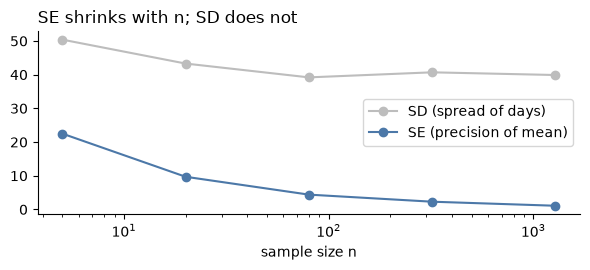

In [11]:
rs = np.random.default_rng(4)
rows = []
for n_ in (5, 20, 80, 320, 1280):
    smp = rs.normal(520, 40, n_)
    rows.append((n_, smp.std(ddof=1), smp.std(ddof=1) / np.sqrt(n_)))
tab = pd.DataFrame(rows, columns=["n", "SD", "SE"]).round(1); display(tab)
plt.figure(figsize=(6, 2.8)); plt.plot(tab.n, tab.SD, marker="o", color=GREY, label="SD (spread of days)"); plt.plot(tab.n, tab.SE, marker="o", color=BLUE, label="SE (precision of mean)")
plt.xscale("log"); plt.xlabel("sample size n"); plt.legend(); plt.title("SE shrinks with n; SD does not", loc="left"); plt.tight_layout(); plt.show()

## 9 · Error bars: always say what they show

An error bar may show **SD, SE or a CI**: very different lengths. Wilke: always state what the bar represents, and show the raw data when you can.

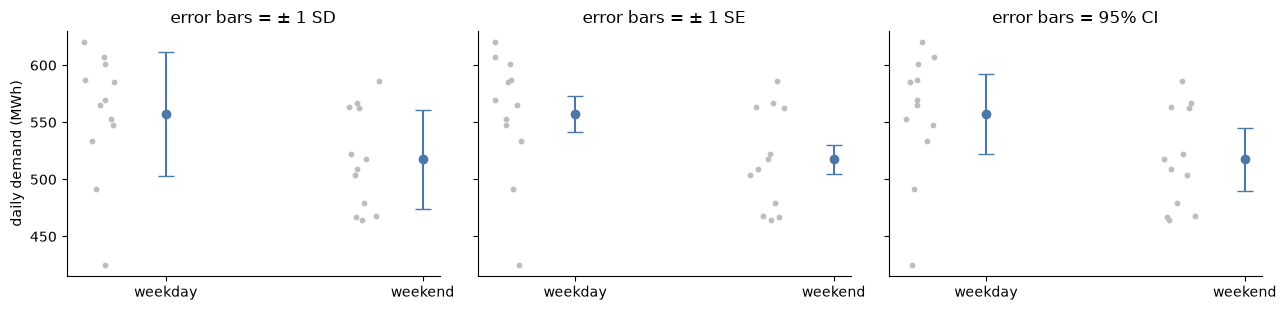

In [12]:
rs = np.random.default_rng(6)
groups = {"weekday": rs.normal(540, 45, 12), "weekend": rs.normal(505, 45, 12)}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for a_, (lab, fn) in zip(ax, [("± 1 SD", lambda v: v.std(ddof=1)), ("± 1 SE", lambda v: v.std(ddof=1) / np.sqrt(len(v))),
                              ("95% CI", lambda v: stats.t.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)))]):
    for k_, (g_, v) in enumerate(groups.items()):
        a_.scatter(np.full(len(v), k_) + rs.normal(0, .04, len(v)) - .25, v, s=10, color=GREY)
        a_.errorbar(k_, v.mean(), yerr=fn(v), fmt="o", color=BLUE, capsize=6)
    a_.set_xticks([0, 1]); a_.set_xticklabels(list(groups)); a_.set_title(f"error bars = {lab}")
ax[0].set_ylabel("daily demand (MWh)"); plt.tight_layout(); plt.show()

### Misreading error bars, and graded alternatives
Viewers treat a bar as a **hard boundary** ("inside = same, outside = different"): Wilke calls this a *deterministic construal error*. Overlap rules of thumb are unreliable, and a bar says nothing about **where** inside the range the value is most likely. Remedies: **graded error bars** (several levels at once) and **confidence strips** that fade smoothly. Use one hue at different saturations so the grading reads as one quantity (Knaflic Ch. 4).

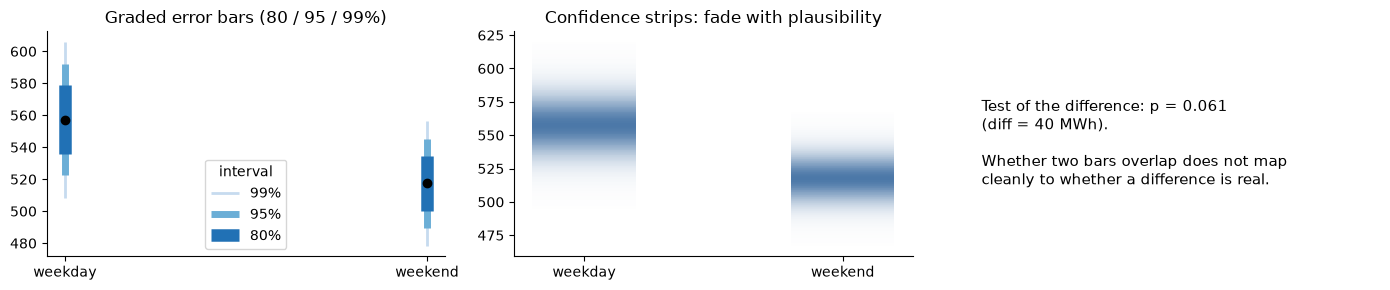

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for k_, (g_, v) in enumerate(groups.items()):
    m_, se_ = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
    for lvl, lw, col in [(.99, 2, "#c6dbef"), (.95, 5, "#6baed6"), (.80, 9, "#2171b5")]:
        h_ = stats.t.ppf(.5 + lvl / 2, len(v) - 1) * se_
        ax[0].plot([k_, k_], [m_ - h_, m_ + h_], color=col, lw=lw, solid_capstyle="butt", label=f"{lvl:.0%}" if k_ == 0 else None)
    ax[0].plot(k_, m_, "o", color="k")
    yy = np.linspace(m_ - 4 * se_, m_ + 4 * se_, 200); dens = stats.t.pdf((yy - m_) / se_, len(v) - 1)
    for y0, y1, d_ in zip(yy[:-1], yy[1:], dens[:-1]): ax[1].fill_between([k_ - .2, k_ + .2], y0, y1, color=BLUE, alpha=float(d_ / dens.max()), lw=0)
ax[0].legend(title="interval"); ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(list(groups)); ax[0].set_title("Graded error bars (80 / 95 / 99%)")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(list(groups)); ax[1].set_title("Confidence strips: fade with plausibility")
diff = groups["weekday"].mean() - groups["weekend"].mean(); tt = stats.ttest_ind(*groups.values())
ax[2].axis("off"); ax[2].text(0, .5, f"Test of the difference: p = {tt.pvalue:.3f}\n(diff = {diff:.0f} MWh).\n\nWhether two bars overlap does not map\ncleanly to whether a difference is real.", fontsize=11, va="center")
plt.tight_layout(); plt.show()

## 10 · Confidence bands and curve fits (Wilke Ch. 16)

For a straight line the band is **curved**: narrowest near the middle of the data, flaring toward the ends. A different model gives a different band, so **state the model**, and always draw the points: the band alone can look more certain than the evidence.

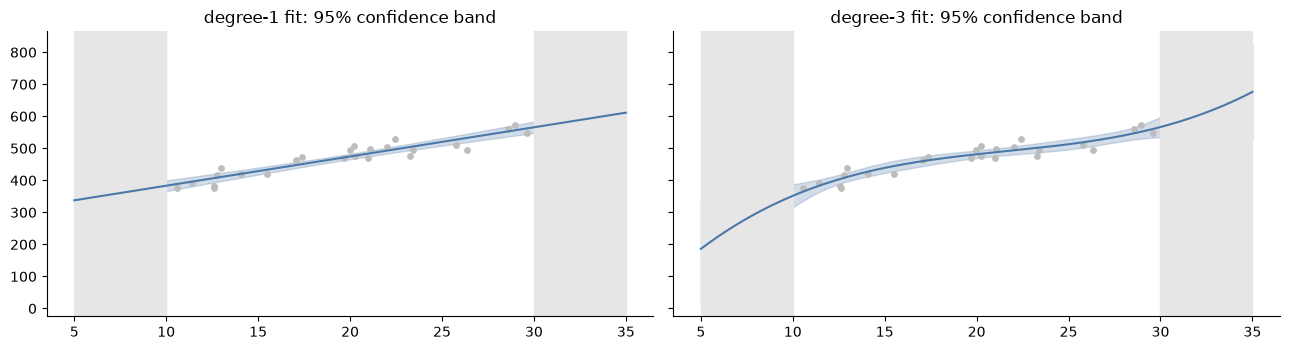

In [14]:
rs = np.random.default_rng(11)
xs_ = np.sort(rs.uniform(10, 30, 25)); ys_ = 300 + 9 * xs_ + rs.normal(0, 25, 25)
gx2 = np.linspace(5, 35, 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for a_, deg in zip(ax, [1, 3]):
    pf = PolynomialFeatures(deg); A = pf.fit_transform(xs_[:, None]); G = pf.transform(gx2[:, None])
    b_ = np.linalg.lstsq(A, ys_, rcond=None)[0]; r_ = ys_ - A @ b_; s2_ = (r_ ** 2).sum() / (len(xs_) - A.shape[1])
    se_ = np.sqrt(s2_ * np.einsum("ij,jk,ik->i", G, np.linalg.inv(A.T @ A), G)); t_ = stats.t.ppf(.975, len(xs_) - A.shape[1])
    a_.fill_between(gx2, G @ b_ - t_ * se_, G @ b_ + t_ * se_, color=BLUE, alpha=.25); a_.plot(gx2, G @ b_, color=BLUE); a_.scatter(xs_, ys_, color=GREY, s=15)
    a_.axvspan(5, 10, color=LIGHT); a_.axvspan(30, 35, color=LIGHT); a_.set_title(f"degree-{deg} fit: 95% confidence band")
ax[1].set_ylim(ax[0].get_ylim()); plt.tight_layout(); plt.show()

## 11 · Graded bands for forecasts

A single narrow band looks reassuring; **graded bands (50 / 80 / 95%)** show how confidence falls with the horizon. Some outcomes leave the inner band; nearly all stay in the outer one. **An inner band is not a guarantee.**

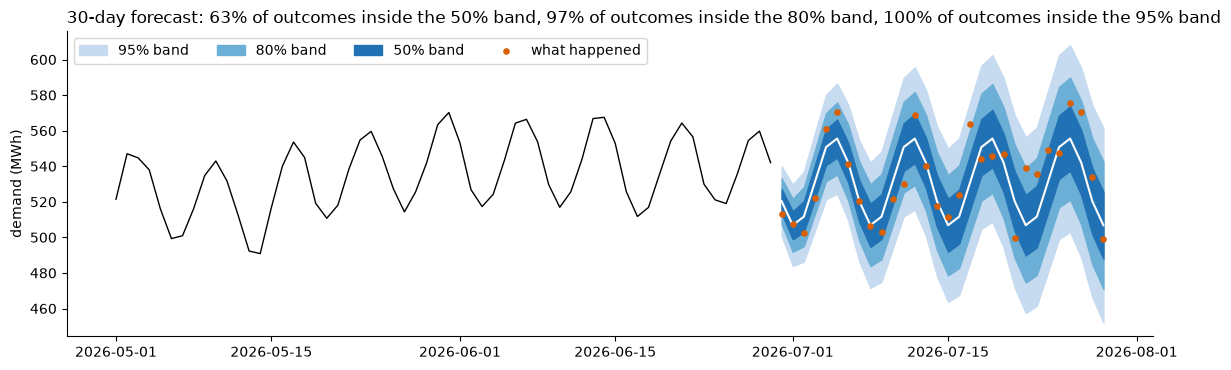

In [15]:
rs = np.random.default_rng(21)
hist_d = pd.date_range("2026-05-01", periods=60, freq="D"); hist_y = 520 + 25 * np.sin(np.arange(60) / 7 * 2 * np.pi) + np.cumsum(rs.normal(0, 4, 60))
h = np.arange(1, 31); fc_d = pd.date_range(hist_d[-1] + pd.Timedelta(days=1), periods=30)
fc_mean = hist_y[-1] + 25 * (np.sin((60 + h - 1) / 7 * 2 * np.pi) - np.sin(59 / 7 * 2 * np.pi)); fc_sd = 6 + 4 * np.sqrt(h)
actual = fc_mean + rs.normal(0, 1, 30) * fc_sd
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(hist_d, hist_y, color="k", lw=1)
for lvl, col in [(.95, "#c6dbef"), (.80, "#6baed6"), (.50, "#2171b5")]:
    zq = stats.norm.ppf(.5 + lvl / 2); ax.fill_between(fc_d, fc_mean - zq * fc_sd, fc_mean + zq * fc_sd, color=col, label=f"{lvl:.0%} band")
ax.plot(fc_d, fc_mean, color="w", lw=1.5); ax.scatter(fc_d, actual, color=ACCENT, s=14, zorder=3, label="what happened")
inside = {lvl: (np.abs(actual - fc_mean) <= stats.norm.ppf(.5 + lvl / 2) * fc_sd).mean() for lvl in (.5, .8, .95)}
ax.legend(loc="upper left", ncol=4); ax.set_ylabel("demand (MWh)")
ax.set_title("30-day forecast: " + ", ".join(f"{v:.0%} of outcomes inside the {k:.0%} band" for k, v in inside.items()), loc="left")
plt.tight_layout(); plt.show()

## 12 · Hypothetical outcome plots (HOPs)

A HOP **animates** random draws from the distribution, one outcome per frame; viewers estimate a probability by how often something happens (Hullman et al. 2015; Kale et al. 2018). On paper we show the frames side by side. Question: *will demand on day 20 exceed 560 MWh?*

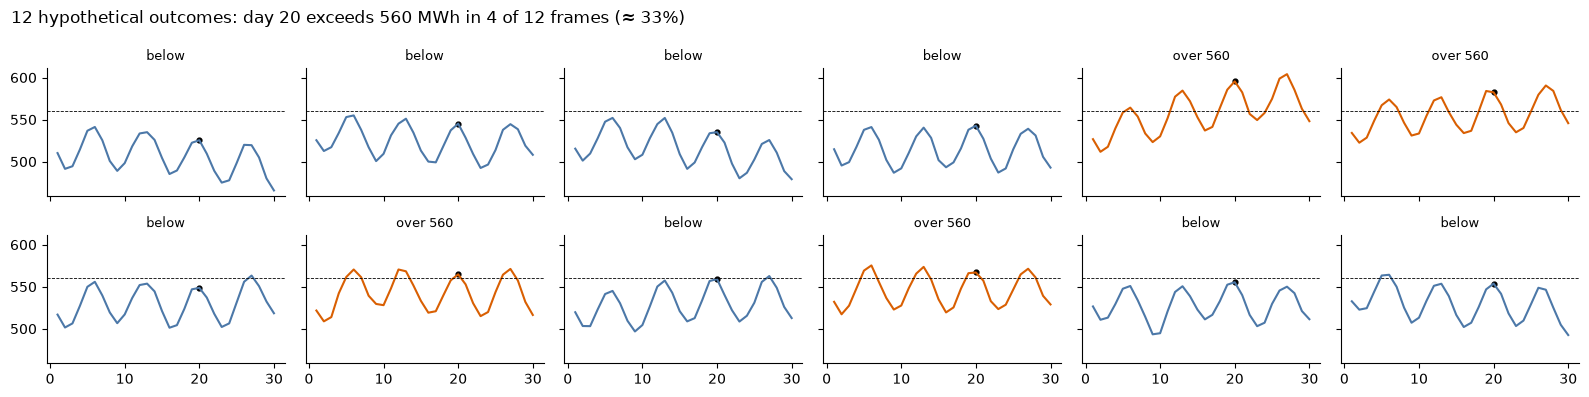

Animated on screen, the same frames would play one at a time; on paper, use quantile dotplots or graded bands.


In [16]:
rs = np.random.default_rng(5)
fig, axs = plt.subplots(2, 6, figsize=(16, 4), sharex=True, sharey=True)
hits = 0
for a_ in axs.flat:
    path = fc_mean + np.cumsum(rs.normal(0, 1, 30)) * 3 + rs.normal(0, 1) * fc_sd * .6
    over = path[19] > 560; hits += over
    a_.plot(h, path, color=ACCENT if over else BLUE); a_.axhline(560, color="k", lw=.6, ls="--"); a_.scatter(20, path[19], color="k", s=12)
    a_.set_title("over 560" if over else "below", fontsize=9)
fig.suptitle(f"12 hypothetical outcomes: day 20 exceeds 560 MWh in {hits} of 12 frames (≈ {hits / 12:.0%})", x=.01, ha="left")
plt.tight_layout(); plt.show()
print("Animated on screen, the same frames would play one at a time; on paper, use quantile dotplots or graded bands.")

## 13 · Distributions and probability plots (Wilke Ch. 7–8)

* Histogram / density: the **shape** (bin width and bandwidth change the picture).
* **ECDF**: reads probability directly; the height at x is the share of values up to x.
* **Q-Q plot**: compares a distribution with a reference (e.g. normal) so residuals can be checked against model assumptions.

Choose the view for the question: shape, probability of exceeding a value, or fit to a reference.

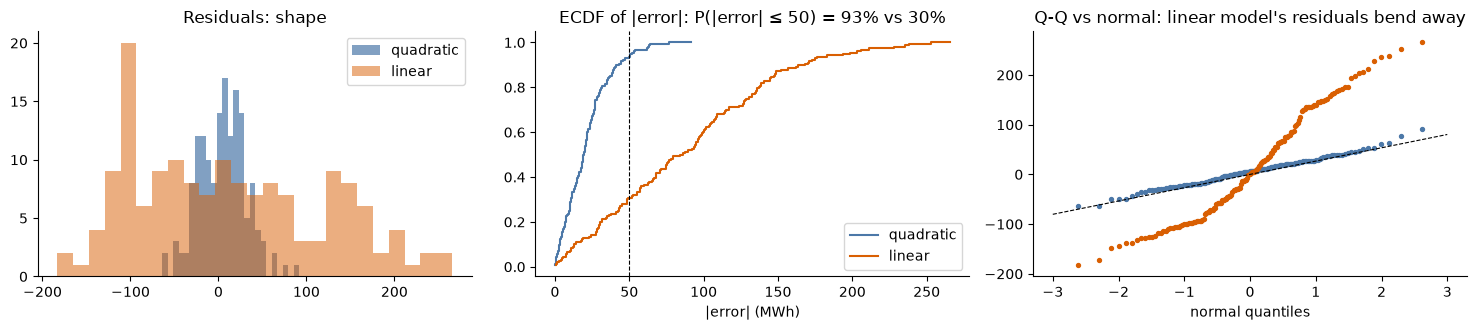

In [17]:
r_lin = en_te.demand - en_te.pred_linear; r_quad = en_te.demand - en_te.pred_quadratic
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].hist(r_quad, bins=25, color=BLUE, alpha=.7, label="quadratic"); ax[0].hist(r_lin, bins=25, color=ACCENT, alpha=.5, label="linear"); ax[0].legend(); ax[0].set_title("Residuals: shape")
for r_, col, lab in [(r_quad, BLUE, "quadratic"), (r_lin, ACCENT, "linear")]:
    x_ = np.sort(np.abs(r_)); ax[1].step(x_, np.arange(1, len(x_) + 1) / len(x_), color=col, label=lab)
ax[1].axvline(50, color="k", ls="--", lw=.8)
ax[1].set_title(f"ECDF of |error|: P(|error| ≤ 50) = {(np.abs(r_quad) <= 50).mean():.0%} vs {(np.abs(r_lin) <= 50).mean():.0%}"); ax[1].legend(); ax[1].set_xlabel("|error| (MWh)")
for r_, col in [(r_quad, BLUE), (r_lin, ACCENT)]:
    (osm, osr), _ = stats.probplot(r_, dist="norm"); ax[2].scatter(osm, osr, s=8, color=col)
ax[2].plot([-3, 3], [-3 * r_quad.std(), 3 * r_quad.std()], "k--", lw=.8); ax[2].set_title("Q-Q vs normal: linear model's residuals bend away"); ax[2].set_xlabel("normal quantiles")
plt.tight_layout(); plt.show()

## 14 · Quantile dotplots and frequency framing (Wilke Ch. 16; Kay et al. 2016)

Slice the predictive distribution into **equal-probability pieces**; each dot carries the same probability (here 20 dots = 5% each). Counting dots gives a **frequency**, not a percentage. Wilke: people reason more reliably with **"of 10 similar cases, about 7…"** than with "70%".

Question: tomorrow is forecast at 31 °C. *How likely is demand above the 700 MWh grid-warning level?*

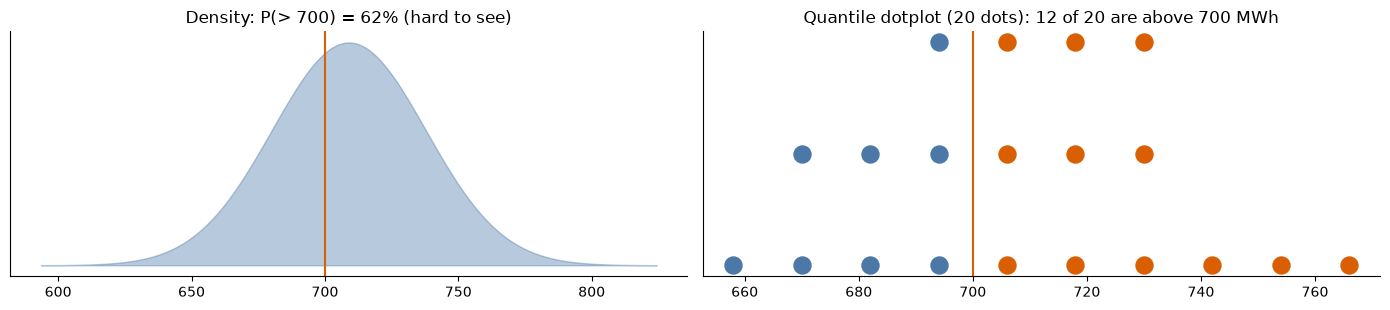

Plain words: 'On days like tomorrow, demand tops 700 MWh about 12 times in 20.'


In [18]:
x0 = pd.DataFrame({"temp_c": [31.0]}); X0 = poly.transform(x0)
mu0 = quad.predict(X0)[0]; sd0 = np.sqrt(s2 + s2 * (X0 @ XtX_inv @ X0.T)[0, 0])
qs = stats.norm.ppf((np.arange(20) + .5) / 20, mu0, sd0)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
xx_ = np.linspace(mu0 - 4 * sd0, mu0 + 4 * sd0, 300); ax[0].fill_between(xx_, stats.norm.pdf(xx_, mu0, sd0), color=BLUE, alpha=.4); ax[0].axvline(700, color=ACCENT)
ax[0].set_title(f"Density: P(> 700) = {stats.norm.sf(700, mu0, sd0):.0%} (hard to see)"); ax[0].set_yticks([])
bw = 12; bins_ = 700 + np.floor((qs - 700) / bw) * bw            # bin edges line up with the 700 threshold
for b_ in np.unique(bins_):
    k_ = np.where(bins_ == b_)[0]
    for j, i in enumerate(k_): ax[1].scatter(b_ + bw / 2, j + .5, s=150, color=ACCENT if qs[i] > 700 else BLUE)
ax[1].axvline(700, color=ACCENT); ax[1].set_yticks([]); n_over = (qs > 700).sum()
ax[1].set_title(f"Quantile dotplot (20 dots): {n_over} of 20 are above 700 MWh")
plt.tight_layout(); plt.show()
print(f"Plain words: 'On days like tomorrow, demand tops 700 MWh about {n_over} times in 20.'")

## 15 · Calibration and the reliability diagram (Guo et al. 2017)

A model is **calibrated** when its stated probabilities match long-run frequencies. Calibration is **separate from accuracy**. Check it on **held-out** data.

**Reliability diagram:** bin predictions by confidence, plot actual accuracy per bin. On the diagonal = calibrated; **below = overconfident**; above = underconfident. Show the **counts** (sparse bins are noisy) and add **error bars** to each bin's accuracy (Wilke Ch. 16). Bin choice matters: compare equal-width and equal-count bins.

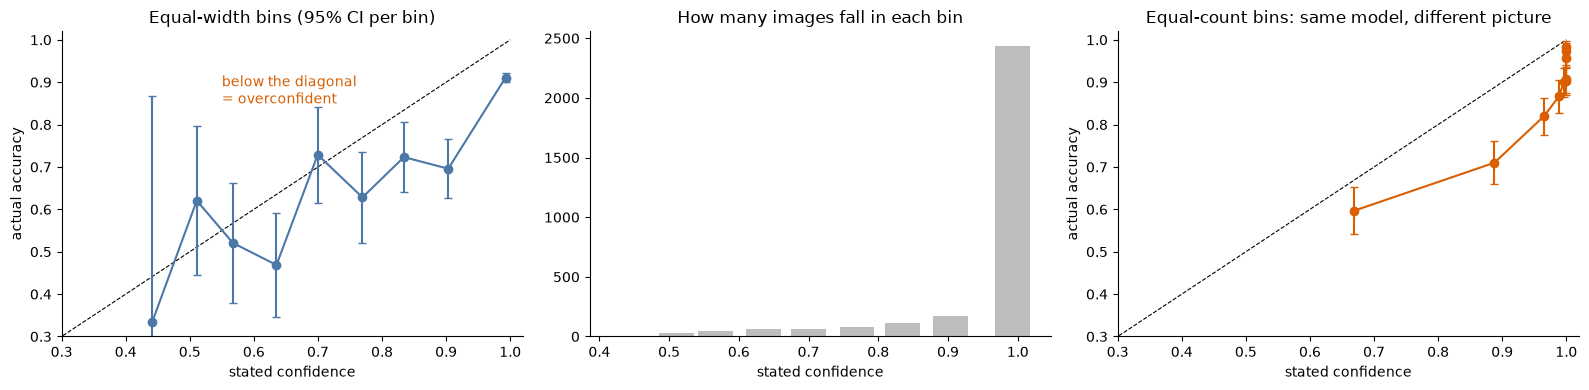

In [19]:
def reliability(conf_, correct_, bins=10, equal_count=False):
    edges = np.quantile(conf_, np.linspace(0, 1, bins + 1)) if equal_count else np.linspace(1 / 3, 1, bins + 1)
    idx = np.clip(np.searchsorted(edges, conf_, side="right") - 1, 0, bins - 1)
    out = pd.DataFrame({"bin": idx, "conf": conf_, "correct": correct_}).groupby("bin").agg(conf=("conf", "mean"), acc=("correct", "mean"), n=("correct", "size"))
    out["se"] = np.sqrt(out.acc * (1 - out.acc) / out.n)
    return out

def draw_reliability(ax, rel, title, color=BLUE):
    ax.plot([0, 1], [0, 1], "--", color="k", lw=.8)
    ax.errorbar(rel.conf, rel.acc, yerr=1.96 * rel.se, fmt="o-", color=color, capsize=3)
    ax.set_xlim(.3, 1.02); ax.set_ylim(.3, 1.02); ax.set_xlabel("stated confidence"); ax.set_ylabel("actual accuracy"); ax.set_title(title)

rel_w, rel_c = reliability(te.confidence.values, te.correct.values), reliability(te.confidence.values, te.correct.values, equal_count=True)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
draw_reliability(ax[0], rel_w, "Equal-width bins (95% CI per bin)"); ax[0].text(.55, .85, "below the diagonal\n= overconfident", color=ACCENT)
ax[1].bar(rel_w.conf, rel_w.n, width=.05, color=GREY); ax[1].set_title("How many images fall in each bin"); ax[1].set_xlabel("stated confidence")
draw_reliability(ax[2], rel_c, "Equal-count bins: same model, different picture", color=ACCENT)
plt.tight_layout(); plt.show()

## 16 · Measuring calibration: ECE and the Brier score

* **ECE** = weighted average over bins of |accuracy − confidence|; lower is better; **depends on the binning**.
* **Brier** = mean of (predicted probability − outcome)²; rewards calibration *and* sharpness. Compare with a baseline (always predicting the base rates).

Report them **with** the reliability diagram, not instead of it.

In [20]:
def ece(conf_, correct_, bins=10, equal_count=False):
    r_ = reliability(conf_, correct_, bins, equal_count); return float((r_.n / r_.n.sum() * (r_.acc - r_.conf).abs()).sum())

def brier(Pm, y_):
    Y = np.eye(Pm.shape[1])[y_]; return float(((Pm - Y) ** 2).sum(axis=1).mean())

base = np.tile(np.bincount(y_tr) / len(y_tr), (len(y_te), 1))
display(pd.DataFrame({"accuracy": [te.correct.mean(), (y_te == base.argmax(1)).mean()],
                      "ECE (10 equal-width)": [ece(conf, pred == y_te), np.nan], "ECE (10 equal-count)": [ece(conf, pred == y_te, equal_count=True), np.nan],
                      "Brier (multi-class)": [brier(P, y_te), brier(base, y_te)]}, index=["Naive Bayes", "always base rates"]).round(3))

,accuracy,ECE (10 equal-width),ECE (10 equal-count),Brier (multi-class)
Naive Bayes,0.862,0.092,0.089,0.235
always base rates,0.449,NaN,NaN,0.616


## 17 · Improving calibration: temperature scaling

Post-hoc, on a **held-out calibration set**: temperature scaling divides the logits by one learned value **T** (Platt scaling and isotonic regression are alternatives). It **leaves the predicted label unchanged**; it only softens or sharpens confidence. **Calibration does not make the model more accurate.** Redraw the reliability diagram to confirm.

learned temperature T = 3.37 | labels unchanged: True | accuracy 0.862 -> 0.862
ECE 0.092 -> 0.056 | Brier 0.235 -> 0.228 | mean confidence 0.950 -> 0.810


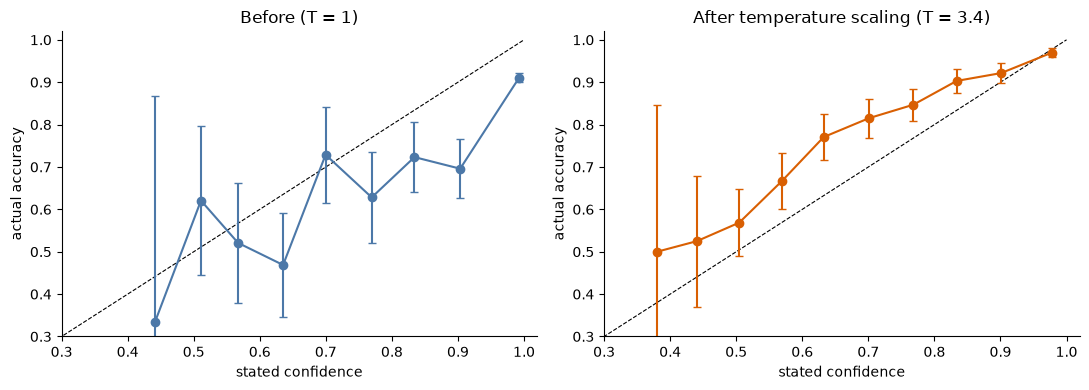

In [21]:
def nll(T, L, y_): return float(-(L / T - logsumexp(L / T, axis=1, keepdims=True))[np.arange(len(y_)), y_].mean())
T = minimize_scalar(lambda t_: nll(t_, logit_cal, y_cal), bounds=(0.5, 50), method="bounded").x
P_T = softmax(logit_te / T, axis=1); conf_T = P_T.max(axis=1)
print(f"learned temperature T = {T:.2f} | labels unchanged: {(P_T.argmax(1) == pred).all()} | accuracy {te.correct.mean():.3f} -> {(P_T.argmax(1) == y_te).mean():.3f}")
print(f"ECE {ece(conf, pred == y_te):.3f} -> {ece(conf_T, pred == y_te):.3f} | Brier {brier(P, y_te):.3f} -> {brier(P_T, y_te):.3f} | mean confidence {conf.mean():.3f} -> {conf_T.mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
draw_reliability(ax[0], reliability(conf, pred == y_te), "Before (T = 1)"); draw_reliability(ax[1], reliability(conf_T, pred == y_te), f"After temperature scaling (T = {T:.1f})", color=ACCENT)
plt.tight_layout(); plt.show()
te["confidence_T"] = conf_T

## 18 · Calibration across classes and groups

A model can look calibrated overall yet be miscalibrated for particular classes or groups. Draw one reliability diagram per class / subgroup as **small multiples on shared axes**, and show **n** so thin groups are not over-read. Here the subgroups are images from **phone cameras** vs **trail cameras** (noisier).

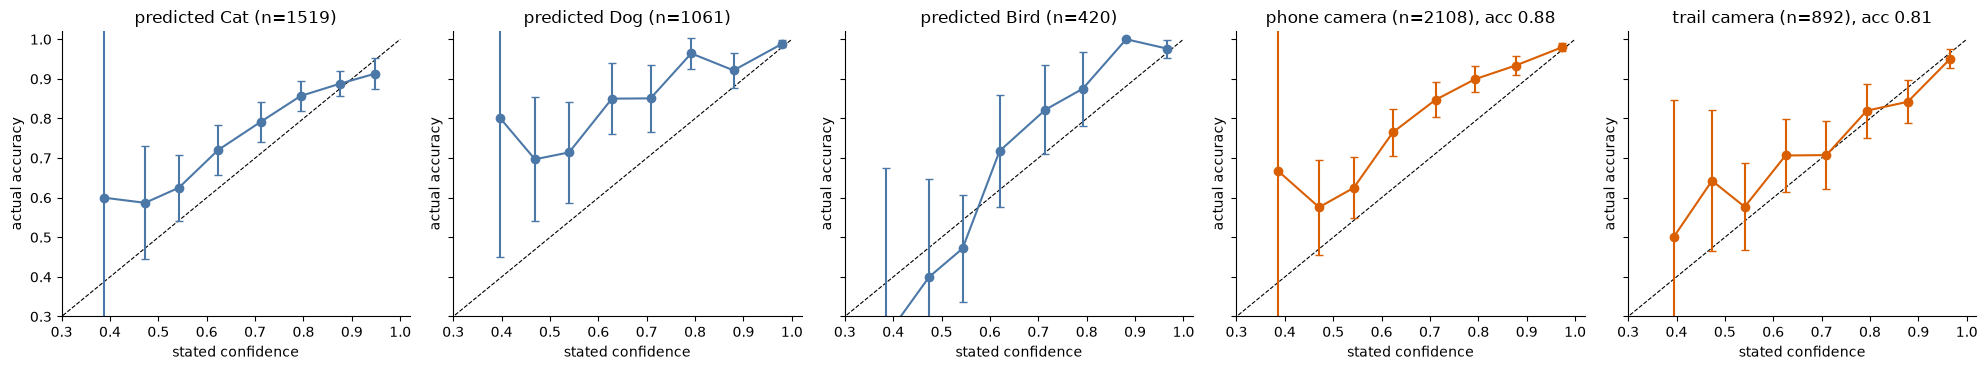

phone camera : mean confidence 0.813, accuracy 0.883, ECE 0.070
trail camera : mean confidence 0.802, accuracy 0.812, ECE 0.036
Confidence minus accuracy after one global T: phone -0.070, trail -0.009. The model never saw trail-camera images in training; one temperature cannot fix a group-specific gap: a finding to investigate, not decoration.


In [22]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8), sharey=True)
for a_, c_ in zip(ax[:3], range(3)):
    m_ = pred == c_
    draw_reliability(a_, reliability(conf_T[m_], (y_te == c_)[m_], bins=8), f"predicted {CLASSES[c_]} (n={m_.sum()})")
for a_, g_ in zip(ax[3:], ["phone camera", "trail camera"]):
    m_ = g_te == g_
    draw_reliability(a_, reliability(conf_T[m_], (pred == y_te)[m_], bins=8), f"{g_} (n={m_.sum()}), acc {(pred == y_te)[m_].mean():.2f}", color=ACCENT)
plt.tight_layout(); plt.show()
for g_ in ["phone camera", "trail camera"]:
    m_ = g_te == g_; print(f"{g_:13s}: mean confidence {conf_T[m_].mean():.3f}, accuracy {(pred == y_te)[m_].mean():.3f}, ECE {ece(conf_T[m_], (pred == y_te)[m_]):.3f}")
gap = {g_: conf_T[g_te == g_].mean() - (pred == y_te)[g_te == g_].mean() for g_ in ['phone camera', 'trail camera']}
print(f"Confidence minus accuracy after one global T: phone {gap['phone camera']:+.3f}, trail {gap['trail camera']:+.3f}. "
      "The model never saw trail-camera images in training; one temperature cannot fix a group-specific gap: a finding to investigate, not decoration.")

## 19 · Confusion matrices

Rows = actual class, columns = predicted; the diagonal is correct. **Row-normalised:** diagonal = recall. **Column-normalised:** diagonal = precision.

**Design** (Knaflic Ch. 4–5, Ware G3.1): one hue with varying saturation (not a rainbow); print the number in each cell; fixed class order; highlight only the few cells that matter.

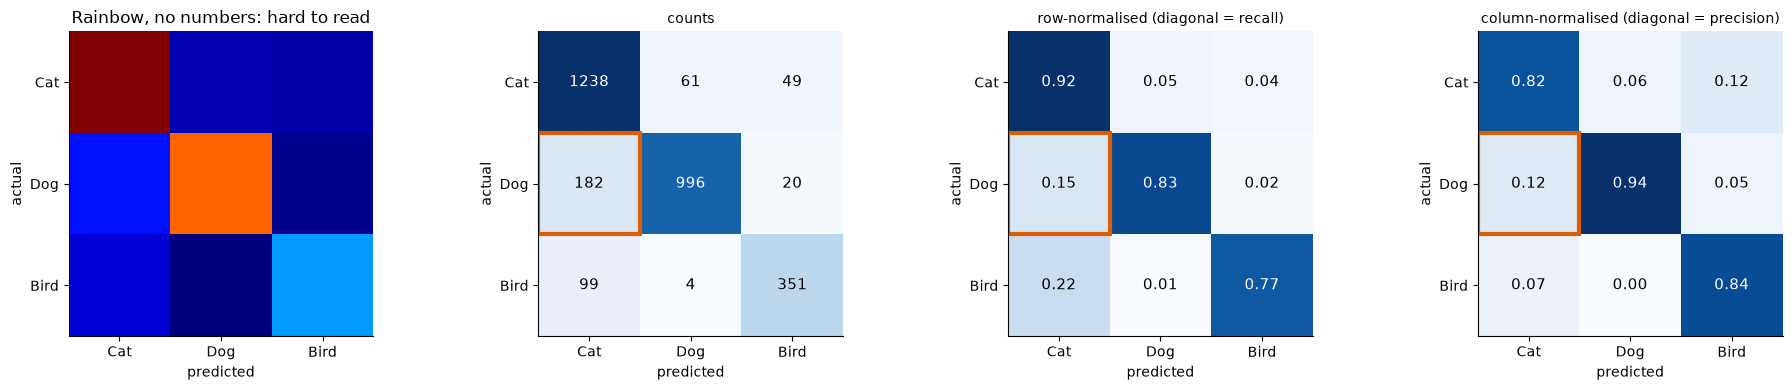

Largest confusion (orange box): actual Dog predicted as Cat (182 images).


In [23]:
cm = pd.crosstab(pd.Series(np.array(CLASSES)[y_te], name="actual"), pd.Series(np.array(CLASSES)[pred], name="predicted")).loc[CLASSES, CLASSES]
views = {"counts": cm, "row-normalised (diagonal = recall)": cm.div(cm.sum(axis=1), axis=0), "column-normalised (diagonal = precision)": cm.div(cm.sum(axis=0), axis=1)}
off = cm.values.copy(); np.fill_diagonal(off, 0); worst = np.unravel_index(off.argmax(), off.shape)
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
ax[0].imshow(cm.values, cmap="jet"); ax[0].set_title("Rainbow, no numbers: hard to read")
for a_, (lab, M) in zip(ax[1:], views.items()):
    a_.imshow(M.values, cmap="Blues")
    for i in range(3):
        for j in range(3):
            v = M.values[i, j]; a_.text(j, i, f"{v:.0f}" if lab == "counts" else f"{v:.2f}", ha="center", va="center", color="w" if v > M.values.max() * .6 else "k", fontsize=11)
    a_.add_patch(plt.Rectangle((worst[1] - .5, worst[0] - .5), 1, 1, fill=False, ec=ACCENT, lw=3)); a_.set_title(lab, fontsize=10)
for a_ in ax: a_.set_xticks(range(3)); a_.set_xticklabels(CLASSES); a_.set_yticks(range(3)); a_.set_yticklabels(CLASSES); a_.set_xlabel("predicted"); a_.set_ylabel("actual")
plt.tight_layout(); plt.show()
print(f"Largest confusion (orange box): actual {CLASSES[worst[0]]} predicted as {CLASSES[worst[1]]} ({off.max()} images).")

## 20 · Performance summaries

| Measure | Definition | Watch out for |
|---|---|---|
| Accuracy | correct / all | misleading when classes are imbalanced |
| Precision | TP / (TP + FP) | ignores missed cases |
| Recall | TP / (TP + FN) | ignores false alarms |
| F1 | harmonic mean of P and R | hides which of the two is weak |
| Macro average | mean of per-class scores | treats rare and common classes alike |
| Support | number of true cases per class | needed to judge each score's reliability |

In [24]:
rep = pd.DataFrame({"precision": np.diag(cm) / cm.sum(axis=0).values, "recall": np.diag(cm) / cm.sum(axis=1).values, "support": cm.sum(axis=1).values}, index=CLASSES)
rep["F1"] = 2 * rep.precision * rep.recall / (rep.precision + rep.recall)
rep.loc["macro average"] = [rep.precision.mean(), rep.recall.mean(), rep.support.sum(), rep.F1.mean()]
display(rep.round(2))
majority = (y_te == np.bincount(y_tr).argmax()).mean()
print(f"Accuracy {te.correct.mean():.2f}; always predicting the majority class ({CLASSES[np.bincount(y_tr).argmax()]}) would already score {majority:.2f}.")

,precision,recall,support,F1
Cat,0.82,0.92,1348,0.86
Dog,0.94,0.83,1198,0.88
Bird,0.84,0.77,454,0.80
macro average,0.86,0.84,3000,0.85


Accuracy 0.86; always predicting the majority class (Cat) would already score 0.45.


## 21 · ROC and precision-recall curves; choosing an operating point

A **ROC** curve plots TPR against FPR as the threshold sweeps (AUC summarizes ranking quality). A **PR** curve is more informative when positives are **rare**. Each point is one threshold: **mark the operating point actually used.** A curve summarizes all thresholds but does not choose one: **pick from the costs**, and show the consequence **in counts per 1,000 cases**.

Task: *Is it a Bird?* (the rare class, 15%). A missed bird costs 5; a false bird alert costs 1.

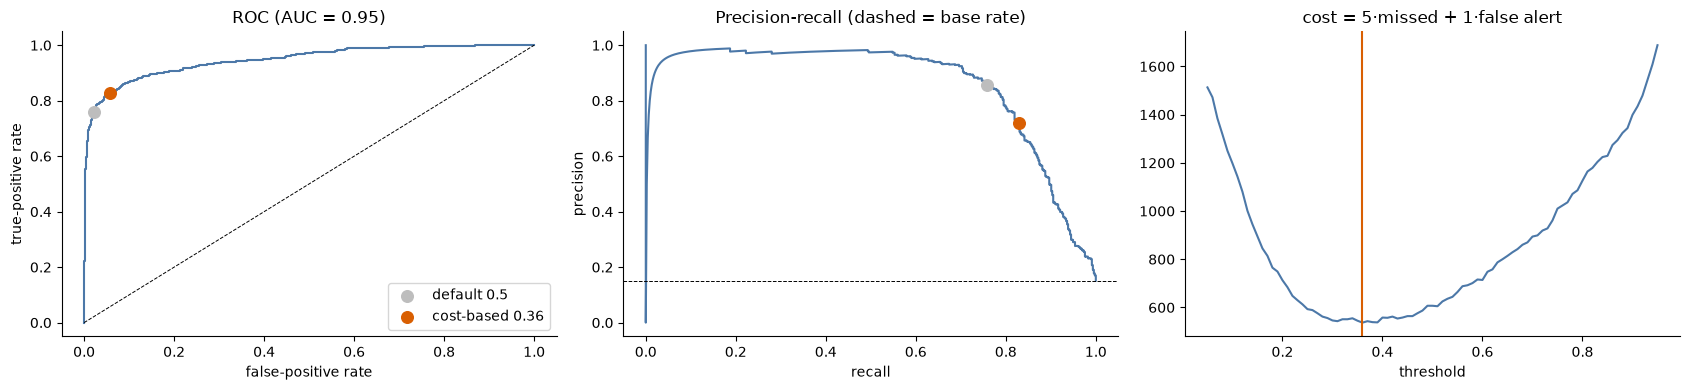

threshold 0.50: per 1,000 images -> 115 birds found, 37 birds missed, 19 false bird alerts
threshold 0.36: per 1,000 images -> 125 birds found, 26 birds missed, 49 false bird alerts


In [25]:
yb, sb = (y_te == 2).astype(int), P_T[:, 2]
fpr, tpr, thr_r = roc_curve(yb, sb); pr_p, pr_r, thr_p = precision_recall_curve(yb, sb)
grid = np.linspace(.05, .95, 91)
cost = [5 * ((sb < t_) & (yb == 1)).sum() + ((sb >= t_) & (yb == 0)).sum() for t_ in grid]
t_best = grid[int(np.argmin(cost))]
op = lambda t_: dict(TP=int(((sb >= t_) & (yb == 1)).sum()), FP=int(((sb >= t_) & (yb == 0)).sum()), FN=int(((sb < t_) & (yb == 1)).sum()))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(fpr, tpr, color=BLUE); ax[0].plot([0, 1], [0, 1], "k--", lw=.7); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate"); ax[0].set_title(f"ROC (AUC = {auc(fpr, tpr):.2f})")
ax[1].plot(pr_r, pr_p, color=BLUE); ax[1].axhline(yb.mean(), color="k", ls="--", lw=.7); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall (dashed = base rate)")
for t_, col, lab in [(.5, GREY, "default 0.5"), (t_best, ACCENT, f"cost-based {t_best:.2f}")]:
    o_ = op(t_); ax[0].scatter(o_["FP"] / (yb == 0).sum(), o_["TP"] / yb.sum(), s=70, color=col, zorder=3, label=lab)
    ax[1].scatter(o_["TP"] / yb.sum(), o_["TP"] / (o_["TP"] + o_["FP"]), s=70, color=col, zorder=3)
ax[0].legend(); ax[2].plot(grid, cost, color=BLUE); ax[2].axvline(t_best, color=ACCENT); ax[2].set_xlabel("threshold"); ax[2].set_title("cost = 5·missed + 1·false alert")
plt.tight_layout(); plt.show()
for t_ in (.5, t_best):
    o_ = op(t_); k_ = 1000 / len(yb)
    print(f"threshold {t_:.2f}: per 1,000 images -> {o_['TP'] * k_:.0f} birds found, {o_['FN'] * k_:.0f} birds missed, {o_['FP'] * k_:.0f} false bird alerts")

## 22 · Uncertainty in AI models: aleatoric versus epistemic

| | Aleatoric | Epistemic |
|---|---|---|
| Source | noise in the data-generating process | limited data or an imperfect model |
| Reducible? | no (with this kind of measurement) | **yes, with more or better data** |
| Typical cue | width of the prediction interval | spread of ensemble / bootstrap fits |
| Largest where | the process is noisy | data are sparse or inputs unfamiliar |

Below: the same noisy process sampled with 25, 100 and 800 points, with a **gap** in the middle. The grey band (noise) stays; the orange spread of bootstrap models shrinks with data but **stays large inside the gap.**

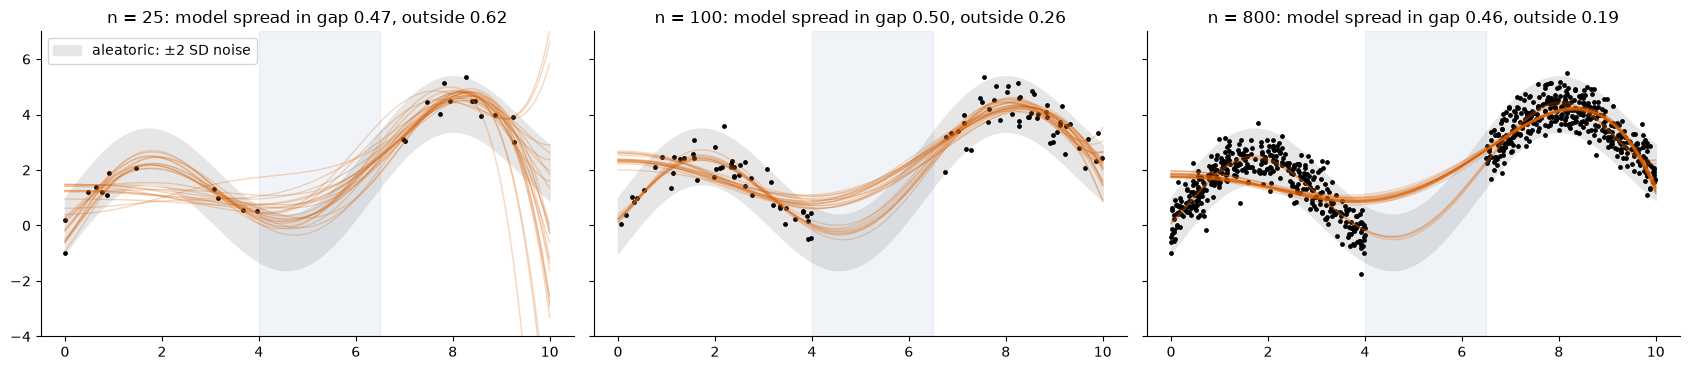

In [26]:
f_true = lambda x: np.sin(x) * 2 + 0.3 * x
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
gxs = np.linspace(0, 10, 200)
for a_, n_ in zip(ax, [25, 100, 800]):
    rs = np.random.default_rng(n_)
    xo = np.r_[rs.uniform(0, 4, n_ // 2), rs.uniform(6.5, 10, n_ - n_ // 2)]; yo = f_true(xo) + rs.normal(0, .5, n_)
    a_.fill_between(gxs, f_true(gxs) - 1, f_true(gxs) + 1, color=LIGHT, label="aleatoric: ±2 SD noise")
    spread = []
    for s_ in range(25):
        bi = rs.integers(0, n_, n_); pf = PolynomialFeatures(6); m_ = LinearRegression().fit(pf.fit_transform(xo[bi, None]), yo[bi])
        p_ = m_.predict(pf.transform(gxs[:, None])); spread.append(p_); a_.plot(gxs, p_, color=ACCENT, alpha=.25, lw=1)
    a_.scatter(xo, yo, s=6, color="k"); a_.axvspan(4, 6.5, color=BLUE, alpha=.08)
    a_.set_title(f"n = {n_}: model spread in gap {np.std(spread, 0)[(gxs > 4) & (gxs < 6.5)].mean():.2f}, outside {np.std(spread, 0)[(gxs < 4) | (gxs > 6.5)].mean():.2f}")
    a_.set_ylim(-4, 7)
ax[0].legend(loc="upper left"); plt.tight_layout(); plt.show()

## 23 · Extrapolation and unfamiliar inputs

A model has little basis for predictions far from its training data, yet it still outputs a confident-looking number. **Show where the training data lie** (a rug, a density, the points), and **widen or fade the band**, or add a warning, where model spread is large. Our electricity model never saw 20–24 °C days or days above 36 °C.

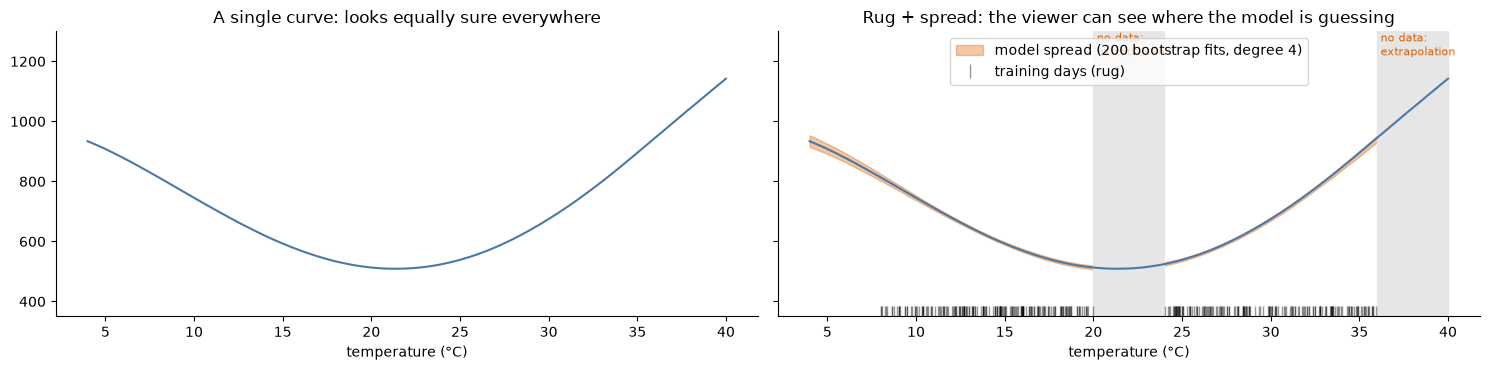

In [27]:
boot_g = []
for s_ in range(200):
    b_ = en_tr.sample(len(en_tr), replace=True, random_state=s_)
    pf = PolynomialFeatures(4); boot_g.append(LinearRegression().fit(pf.fit_transform(b_[["temp_c"]]), b_.demand).predict(pf.transform(pd.DataFrame({"temp_c": gx}))))
boot_g = np.array(boot_g); lo_g, hi_g = np.percentile(boot_g, [2.5, 97.5], 0)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
ax[0].plot(gx, np.median(boot_g, 0), color=BLUE); ax[0].set_title("A single curve: looks equally sure everywhere"); ax[0].set_ylim(350, 1300)
ax[1].fill_between(gx, lo_g, hi_g, color=ACCENT, alpha=.35, label="model spread (200 bootstrap fits, degree 4)")
ax[1].plot(gx, np.median(boot_g, 0), color=BLUE)
ax[1].plot(en_tr.temp_c, np.full(len(en_tr), 360), "|", color="k", alpha=.4, ms=10, label="training days (rug)")
for x0_, x1_ in [(20, 24), (36, 40)]: ax[1].axvspan(x0_, x1_, color=LIGHT); ax[1].text(x0_ + .2, 1220, "no data:\nextrapolation", fontsize=8, color=ACCENT)
ax[1].legend(loc="upper center"); ax[1].set_title("Rug + spread: the viewer can see where the model is guessing")
for a_ in ax: a_.set_xlabel("temperature (°C)")
plt.tight_layout(); plt.show()

## 24 · Bayesian posteriors and credible intervals (Wilke Ch. 16)

A Bayesian analysis returns a **posterior distribution**. A **credible interval** holds a stated probability of the quantity, given the data and the prior; a frequentist **confidence interval** is a statement about the procedure. Draw the posterior itself, not only an interval, and **say which kind you show**.

Example: the bird detector was checked on a small new site: **18 of 22** flagged images were really birds. What is its precision there?

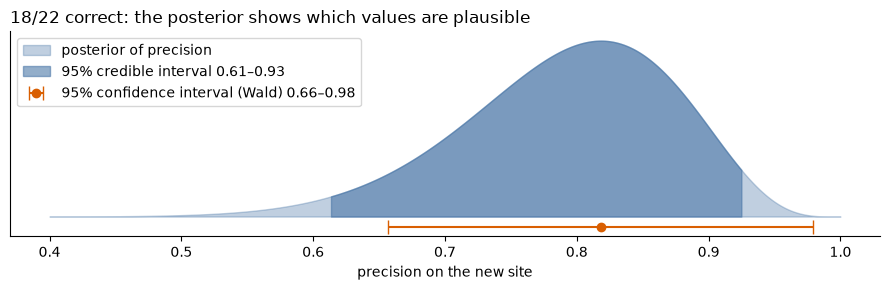

P(precision > 0.9 | data) = 7%  <- a direct probability statement only the Bayesian view gives.


In [28]:
k_, n_ = 18, 22
post = stats.beta(1 + k_, 1 + n_ - k_)                         # uniform prior
ci_lo, ci_hi = post.ppf([.025, .975])
p_hat = k_ / n_; wald = 1.96 * np.sqrt(p_hat * (1 - p_hat) / n_)
xp = np.linspace(.4, 1, 400)
plt.figure(figsize=(9, 3)); plt.fill_between(xp, post.pdf(xp), color=BLUE, alpha=.35, label="posterior of precision")
m_ = (xp >= ci_lo) & (xp <= ci_hi); plt.fill_between(xp[m_], post.pdf(xp[m_]), color=BLUE, alpha=.6, label=f"95% credible interval {ci_lo:.2f}–{ci_hi:.2f}")
plt.errorbar(p_hat, -0.3, xerr=wald, fmt="o", color=ACCENT, capsize=5, label=f"95% confidence interval (Wald) {p_hat - wald:.2f}–{min(p_hat + wald, 1):.2f}")
plt.legend(loc="upper left"); plt.yticks([]); plt.xlabel("precision on the new site"); plt.title(f"{k_}/{n_} correct: the posterior shows which values are plausible", loc="left"); plt.tight_layout(); plt.show()
print(f"P(precision > 0.9 | data) = {post.sf(.9):.0%}  <- a direct probability statement only the Bayesian view gives.")

## 25 · Prediction sets for classification (conformal prediction)

Instead of one label, return a **set of plausible labels** that contains the true label with a chosen frequency (here 90%), under exchangeability (Angelopoulos & Bates 2021). **Set size is a readable uncertainty signal**: one label = confident, several = unsure.

threshold: include every class with probability ≥ 0.35 | coverage on test = 90.3% (target 90%)


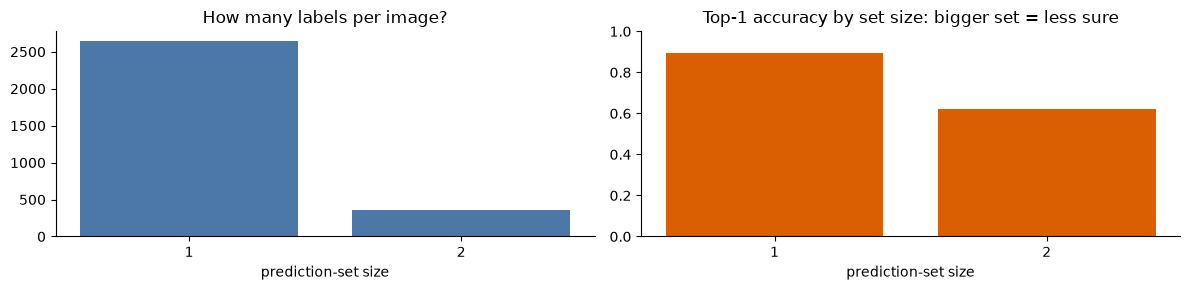

image 5: top-1 'Cat' -> show as {Cat, Bird} (true: Bird)
image 8: top-1 'Cat' -> show as {Cat, Dog} (true: Dog)
image 9: top-1 'Cat' -> show as {Cat, Bird} (true: Cat)


In [29]:
P_cal_T = softmax(logit_cal / T, axis=1)
scores_cal = 1 - P_cal_T[np.arange(len(y_cal)), y_cal]                 # nonconformity: 1 - prob of the true class
qhat_c = np.quantile(scores_cal, np.ceil((len(y_cal) + 1) * .9) / len(y_cal))
sets = P_T >= 1 - qhat_c
size = sets.sum(axis=1); covered = sets[np.arange(len(y_te)), y_te]
print(f"threshold: include every class with probability ≥ {1 - qhat_c:.2f} | coverage on test = {covered.mean():.1%} (target 90%)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
vc = pd.Series(size).value_counts().sort_index(); ax[0].bar(vc.index.astype(str), vc.values, color=BLUE); ax[0].set_xlabel("prediction-set size"); ax[0].set_title("How many labels per image?")
acc_by = pd.Series(pred == y_te).groupby(size).mean(); ax[1].bar(acc_by.index.astype(str), acc_by.values, color=ACCENT); ax[1].set_ylim(0, 1)
ax[1].set_xlabel("prediction-set size"); ax[1].set_title("Top-1 accuracy by set size: bigger set = less sure"); plt.tight_layout(); plt.show()
for i in te.index[size == 2][:3]:
    print(f"image {i}: top-1 '{CLASSES[pred[i]]}' -> show as {{{', '.join(c for c, s in zip(CLASSES, sets[i]) if s)}}} (true: {CLASSES[y_te[i]]})")

## 26 · Communicating uncertainty without misleading users

Show a range or distribution, not only a point · say what the display shows and how it was computed · avoid hard edges that invite deterministic readings · frequencies and plain language · test with real users.

| Display | Likely misreading | Remedy |
|---|---|---|
| Unlabelled error bar | treated as one specific interval | state SD, SE or CI in the caption |
| Single narrow band | "the outcome will be inside" | graded bands; simulate outcomes |
| Percent probability | number hard to grasp | frequency framing, dotplots |
| Confidence score | read as a true probability | check calibration; label it |
| Overall accuracy | assumed good for every class | per-class precision and recall |
| Smooth extrapolated curve | trusted outside the data | show the data range; widen the band |

### Matching the display to the audience (Knaflic Ch. 4–5)
Experts can read distributions and reliability curves; general audiences need a **sentence and a simple picture**. Text is your friend: label directly, title with the takeaway, and **write the uncertainty in plain words**. Below: the same forecast, before and after.

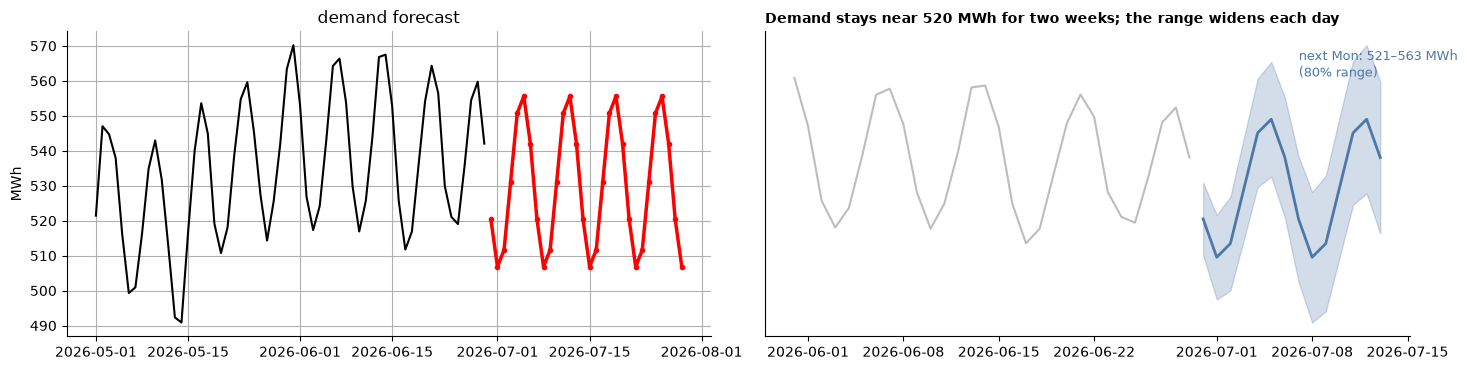

Expect 521–563 MWh (80% range): in about 2 of 10 similar weeks it will fall outside.


In [30]:
def plain_words(lo, hi, level, unit):
    return f"Expect {lo:.0f}–{hi:.0f} {unit} ({level:.0%} range): in about {round((1 - level) * 10)} of 10 similar weeks it will fall outside."

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
ax[0].plot(hist_d, hist_y, color="k"); ax[0].plot(fc_d, fc_mean, color="red", lw=2.5, marker="o", ms=3)
ax[0].grid(True); ax[0].set_title("demand forecast"); ax[0].set_ylabel("MWh")
ax[1].plot(hist_d[-30:], hist_y[-30:], color=GREY)
zq = stats.norm.ppf(.9); ax[1].fill_between(fc_d[:14], (fc_mean - zq * fc_sd)[:14], (fc_mean + zq * fc_sd)[:14], color=BLUE, alpha=.25)
ax[1].plot(fc_d[:14], fc_mean[:14], color=BLUE, lw=2); ax[1].set_yticks([])
d7 = 6; ax[1].annotate(f"next {fc_d[d7]:%a}: {fc_mean[d7] - zq * fc_sd[d7]:.0f}–{fc_mean[d7] + zq * fc_sd[d7]:.0f} MWh\n(80% range)", (fc_d[d7], fc_mean[d7] + zq * fc_sd[d7]),
                       xytext=(10, 15), textcoords="offset points", color=BLUE, fontsize=9)
ax[1].set_title("Demand stays near 520 MWh for two weeks; the range widens each day", loc="left", fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()
print(plain_words(fc_mean[d7] - zq * fc_sd[d7], fc_mean[d7] + zq * fc_sd[d7], .8, "MWh"))

## 27 · Attention, colour and salience (Knaflic Ch. 4–5; Ware Ch. 5)

* **Focus attention:** preattentive attributes (position, size, colour, bold) direct the eye; use them sparingly. Highlight at most ~10% of the visual (Lidwell et al., cited by Knaflic).
* **Colour for uncertainty:** one hue at varying saturation reads as one quantity; a rainbow invites false categories. Chroma/grey encode only a few levels (Ware G4.6, G3.1): back colour up with position or labels.
* **Salience:** the bold point estimate dominates the thin band around it (G1.2, G1.3). **G8.6**: make glyphs more salient when a critical value is reached, e.g. when an interval **crosses a decision threshold**.
* **Encode quantities accurately:** length / position for quantity (G5.15), never 3-D volume (G5.16); a **diverging** colormap with a neutral middle for signed residuals (G4.24).

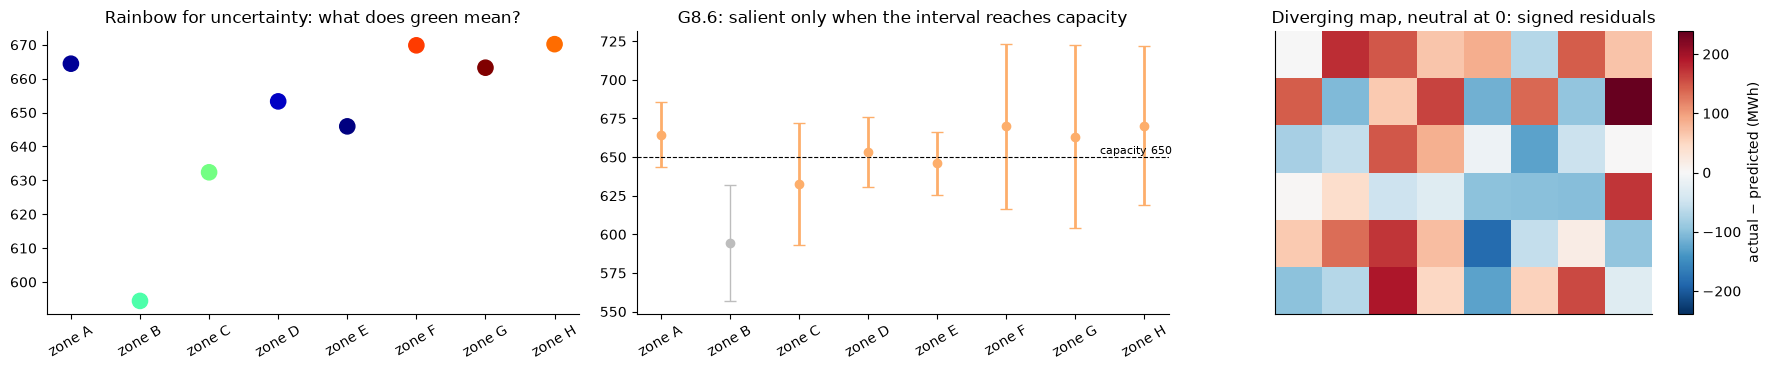

In [31]:
rs = np.random.default_rng(9)
sites = [f"zone {c}" for c in "ABCDEFGH"]; est = rs.uniform(560, 680, 8); half = rs.uniform(20, 60, 8)
crosses = (est + half > 650) & (est - half < 650); over = est - half >= 650
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
ax[0].scatter(range(8), est, c=half, cmap="jet", s=120); ax[0].set_xticks(range(8)); ax[0].set_xticklabels(sites, rotation=30); ax[0].set_title("Rainbow for uncertainty: what does green mean?")
for i in range(8):
    col = ACCENT if over[i] else ("#fdae6b" if crosses[i] else GREY)
    ax[1].errorbar(i, est[i], yerr=half[i], fmt="o", color=col, capsize=4, lw=2 if col != GREY else 1)
ax[1].axhline(650, color="k", ls="--", lw=.8); ax[1].text(7.4, 652, "capacity 650", fontsize=8, ha="right")
ax[1].set_xticks(range(8)); ax[1].set_xticklabels(sites, rotation=30); ax[1].set_title("G8.6: salient only when the interval reaches capacity")
resid_grid = (en_te.demand - en_te.pred_linear).values[:48].reshape(6, 8)
im = ax[2].imshow(resid_grid, cmap="RdBu_r", vmin=-np.abs(resid_grid).max(), vmax=np.abs(resid_grid).max()); fig.colorbar(im, ax=ax[2], label="actual − predicted (MWh)")
ax[2].set_title("Diverging map, neutral at 0: signed residuals"); ax[2].set_xticks([]); ax[2].set_yticks([])
plt.tight_layout(); plt.show()

## 28 · Comparing model confidence and actual correctness

Four views: the **reliability diagram** (Section 15) · **confidence histograms split by correct / incorrect** · **accuracy by confidence bin** with counts and error bars · a **list of high-confidence errors**.

### Confidence thresholds and abstention
Raise the threshold and the model answers fewer cases with higher accuracy: **coverage vs accuracy**. Errors remain even at the highest confidence.

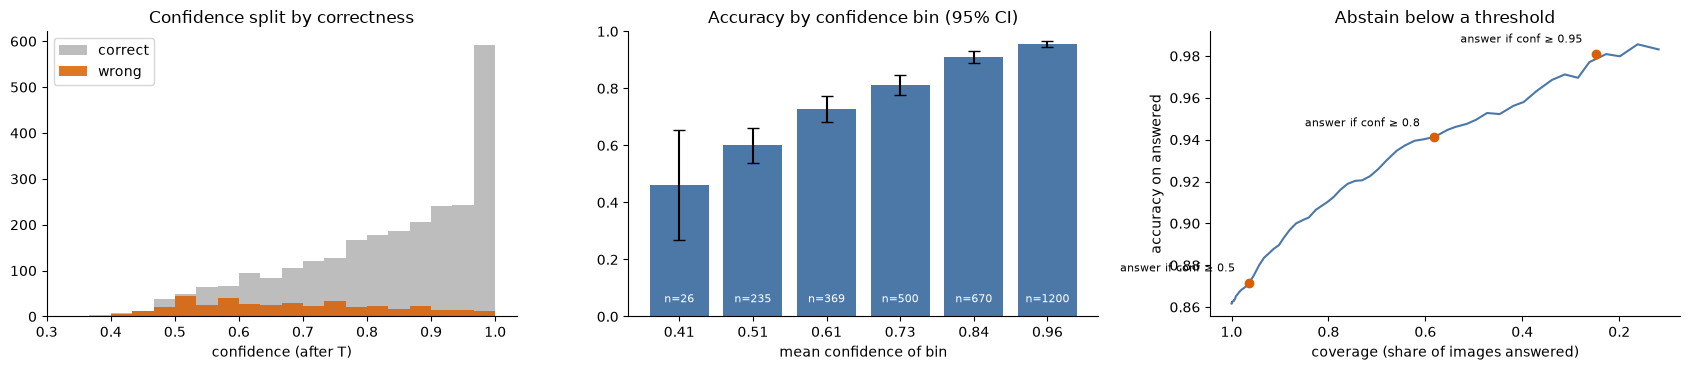

High-confidence errors (confidence ≥ 0.9): 41 images. The worst eight:


,true,pred,confidence_T,p_Cat,p_Dog,p_Bird,source
505,Dog,Bird,1.000,0.0,0.0,1.0,phone camera
1823,Cat,Dog,0.998,0.0,1.0,0.0,phone camera
2024,Cat,Dog,0.996,0.0,1.0,0.0,phone camera
1989,Cat,Dog,0.995,0.0,1.0,0.0,trail camera
2044,Dog,Cat,0.994,1.0,0.0,0.0,trail camera
2605,Bird,Dog,0.991,0.0,1.0,0.0,trail camera
1654,Dog,Cat,0.985,1.0,0.0,0.0,trail camera
1041,Cat,Dog,0.976,0.0,1.0,0.0,trail camera


Inspect these with the image and the probability vector: label noise, data shift or a missing class are typical causes. Track their number over time.


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
bins = np.linspace(1 / 3, 1, 21)
ax[0].hist(conf_T[pred == y_te], bins=bins, color=GREY, label="correct"); ax[0].hist(conf_T[pred != y_te], bins=bins, color=ACCENT, alpha=.85, label="wrong")
ax[0].legend(); ax[0].set_xlabel("confidence (after T)"); ax[0].set_title("Confidence split by correctness")
rb = reliability(conf_T, pred == y_te, bins=6)
ax[1].bar(range(len(rb)), rb.acc, yerr=1.96 * rb.se, color=BLUE, capsize=4)
for i, (a_, n_) in enumerate(zip(rb.acc, rb.n)): ax[1].text(i, .05, f"n={n_}", ha="center", color="w", fontsize=8)
ax[1].set_xticks(range(len(rb))); ax[1].set_xticklabels([f"{c:.2f}" for c in rb.conf]); ax[1].set_xlabel("mean confidence of bin"); ax[1].set_ylim(0, 1); ax[1].set_title("Accuracy by confidence bin (95% CI)")
ths = np.linspace(1 / 3, .99, 60)
cov = [(conf_T >= t_).mean() for t_ in ths]; acc_ = [(pred == y_te)[conf_T >= t_].mean() for t_ in ths]
ax[2].plot(cov, acc_, color=BLUE)
for t_ in (.5, .8, .95):
    c_, a_ = (conf_T >= t_).mean(), (pred == y_te)[conf_T >= t_].mean(); ax[2].scatter(c_, a_, color=ACCENT, zorder=3); ax[2].annotate(f"answer if conf ≥ {t_}", (c_, a_), xytext=(-10, 8), textcoords="offset points", fontsize=8, ha="right")
ax[2].set_xlabel("coverage (share of images answered)"); ax[2].set_ylabel("accuracy on answered"); ax[2].invert_xaxis(); ax[2].set_title("Abstain below a threshold")
plt.tight_layout(); plt.show()
hc = te.assign(confidence_T=conf_T)[(pred != y_te)].sort_values("confidence_T", ascending=False).head(8)
print(f"High-confidence errors (confidence ≥ 0.9): {((conf_T >= .9) & (pred != y_te)).sum()} images. The worst eight:")
display(hc[["true", "pred", "confidence_T", "p_Cat", "p_Dog", "p_Bird", "source"]].round(3))
print("Inspect these with the image and the probability vector: label noise, data shift or a missing class are typical causes. Track their number over time.")

## 29 · Putting it together: a model performance view
Headline: a takeaway title, the key metric **with its uncertainty** · confusion matrix and per-class precision/recall, largest confusion highlighted · reliability diagram with counts, plus confidence by correctness · plain-language note · **hierarchy and restraint**.

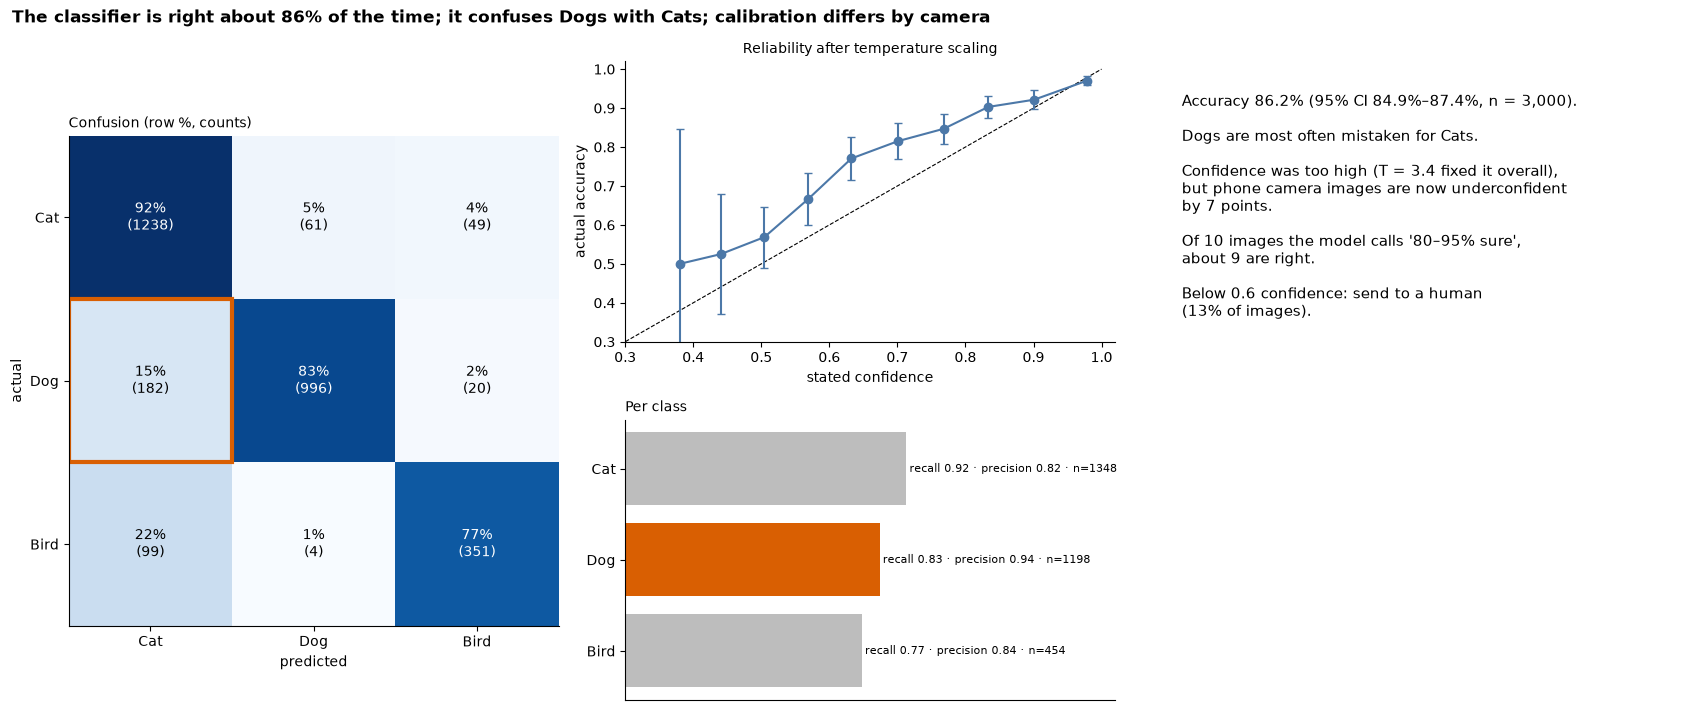

In [33]:
acc_ = (pred == y_te).mean(); se_acc = np.sqrt(acc_ * (1 - acc_) / len(y_te))
g_worst = max(gap, key=lambda k: abs(gap[k])); g_word = "overconfident" if gap[g_worst] > 0 else "underconfident"
fig = plt.figure(figsize=(17, 7.2)); gs = fig.add_gridspec(2, 3)
a0 = fig.add_subplot(gs[:, 0]); a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, 1]); a3 = fig.add_subplot(gs[:, 2])
M = views["row-normalised (diagonal = recall)"].values
a0.imshow(M, cmap="Blues")
for i in range(3):
    for j in range(3): a0.text(j, i, f"{M[i, j]:.0%}\n({cm.values[i, j]})", ha="center", va="center", color="w" if M[i, j] > .6 else "k")
a0.add_patch(plt.Rectangle((worst[1] - .5, worst[0] - .5), 1, 1, fill=False, ec=ACCENT, lw=3))
a0.set_xticks(range(3)); a0.set_xticklabels(CLASSES); a0.set_yticks(range(3)); a0.set_yticklabels(CLASSES); a0.set_xlabel("predicted"); a0.set_ylabel("actual")
a0.set_title("Confusion (row %, counts)", loc="left", fontsize=10)
draw_reliability(a1, reliability(conf_T, pred == y_te), "Reliability after temperature scaling"); a1.title.set_fontsize(10)
a2.barh(CLASSES[::-1], rep.loc[CLASSES[::-1], "recall"], color=[ACCENT if c == CLASSES[worst[0]] else GREY for c in CLASSES[::-1]])
for i, c in enumerate(CLASSES[::-1]): a2.text(rep.loc[c, "recall"] + .01, i, f"recall {rep.loc[c, 'recall']:.2f} · precision {rep.loc[c, 'precision']:.2f} · n={int(rep.loc[c, 'support'])}", va="center", fontsize=8)
a2.set_xlim(0, 1.6); a2.set_xticks([]); a2.set_title("Per class", loc="left", fontsize=10)
a3.axis("off")
note = (f"Accuracy {acc_:.1%} (95% CI {acc_ - 1.96 * se_acc:.1%}–{acc_ + 1.96 * se_acc:.1%}, n = {len(y_te):,}).\n\n"
        f"{CLASSES[worst[0]]}s are most often mistaken for {CLASSES[worst[1]]}s.\n\n"
        f"Confidence was too high (T = {T:.1f} fixed it overall),\nbut {g_worst} images are now {g_word}\nby {abs(gap[g_worst]) * 100:.0f} points.\n\n"
        f"Of 10 images the model calls '80–95% sure',\nabout {round(float(np.mean((pred == y_te)[(conf_T >= .8) & (conf_T < .95)])) * 10)} are right.\n\n"
        f"Below 0.6 confidence: send to a human\n({(conf_T < .6).mean():.0%} of images).")
a3.text(0, .95, note, va="top", fontsize=10.5, transform=a3.transAxes)
fig.suptitle(f"The classifier is right about {acc_:.0%} of the time; it confuses {CLASSES[worst[0]]}s with {CLASSES[worst[1]]}s; calibration differs by camera",
             x=.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 30 · Worked numericals
### Numerical 1: softmax probabilities and temperature

In [34]:
z = np.array([2.0, 1.0, 0.1])
for T_ in (1, 2):
    e = np.exp(z / T_); p_ = e / e.sum()
    print(f"T = {T_}: exp(z/T) = {np.round(e, 3)}, sum = {e.sum():.3f} -> p = {np.round(p_, 3)} | top class {p_.argmax()} | margin {np.sort(p_)[-1] - np.sort(p_)[-2]:.2f}")
print("Temperature scaling softens confidence; the top class does not change.")

T = 1: exp(z/T) = [7.389 2.718 1.105], sum = 11.213 -> p = [0.659 0.242 0.099] | top class 0 | margin 0.42
T = 2: exp(z/T) = [2.718 1.649 1.051], sum = 5.418 -> p = [0.502 0.304 0.194] | top class 0 | margin 0.20
Temperature scaling softens confidence; the top class does not change.


### Numerical 2: expected calibration error
1,000 predictions in three bins: (confidence 0.55, accuracy 0.50, n = 200), (0.75, 0.65, n = 500), (0.95, 0.80, n = 300).

In [35]:
b = pd.DataFrame({"conf": [.55, .75, .95], "acc": [.50, .65, .80], "n": [200, 500, 300]}); b["w"] = b.n / b.n.sum(); b["w|acc-conf|"] = b.w * (b.acc - b.conf).abs()
display(b)
print(f"ECE = {b['w|acc-conf|'].sum():.3f} | average confidence = {(b.w * b.conf).sum():.3f} | overall accuracy = {(b.w * b.acc).sum():.3f}  -> overconfident, mostly in the top bin")

,conf,acc,n,w,w|acc-conf|
0,0.55,0.50,200,0.2,0.010
1,0.75,0.65,500,0.5,0.050
2,0.95,0.80,300,0.3,0.045


ECE = 0.105 | average confidence = 0.770 | overall accuracy = 0.665  -> overconfident, mostly in the top bin


### Numerical 3: Brier score
Predicted probabilities 0.9, 0.8, 0.3, 0.6 of an event; outcomes 1, 1, 0, 0.

In [36]:
p_ = np.array([.9, .8, .3, .6]); o_ = np.array([1, 1, 0, 0])
print("squared errors:", np.round((p_ - o_) ** 2, 2), f"-> Brier = {((p_ - o_) ** 2).mean():.3f} | always 0.5 -> {((.5 - o_) ** 2).mean():.2f}")

squared errors: [0.01 0.04 0.09 0.36] -> Brier = 0.125 | always 0.5 -> 0.25


### Numerical 4: confidence interval versus prediction interval
At a given x a regression predicts 50; residual SD = 4; SE of the mean prediction = 1. 95% intervals with 1.96.

In [37]:
yhat, s_res, se_m = 50, 4, 1
se_p = np.sqrt(s_res ** 2 + se_m ** 2)
print(f"CI for the mean : {yhat} ± 1.96 × {se_m} = {yhat - 1.96 * se_m:.2f} to {yhat + 1.96 * se_m:.2f} (width {2 * 1.96 * se_m:.1f})")
print(f"PI for a new case: SE = sqrt({s_res}² + {se_m}²) = {se_p:.2f}; {yhat} ± 1.96 × {se_p:.2f} = {yhat - 1.96 * se_p:.2f} to {yhat + 1.96 * se_p:.2f} (width {2 * 1.96 * se_p:.1f}) -> about 4x wider")

CI for the mean : 50 ± 1.96 × 1 = 48.04 to 51.96 (width 3.9)
PI for a new case: SE = sqrt(4² + 1²) = 4.12; 50 ± 1.96 × 4.12 = 41.92 to 58.08 (width 16.2) -> about 4x wider


### Numerical 5: metrics from a confusion matrix
Actual (rows) vs predicted (columns) for Cat, Dog, Bird: Cat [50, 5, 5], Dog [10, 40, 10], Bird [2, 3, 25].

In [38]:
C = pd.DataFrame([[50, 5, 5], [10, 40, 10], [2, 3, 25]], index=CLASSES, columns=CLASSES)
prec, rec = np.diag(C) / C.sum(axis=0), np.diag(C) / C.sum(axis=1)
f1 = 2 * prec * rec / (prec + rec)
display(pd.DataFrame({"precision": prec, "recall": rec, "F1": f1}).round(2))
print(f"accuracy = {np.trace(C)} / {C.values.sum()} = {np.trace(C) / C.values.sum():.2f} | macro-F1 = {f1.mean():.2f}")
print("Dogs are missed most (recall 0.67); a 'Bird' prediction is least trustworthy (precision 0.63).")

,precision,recall,F1
Cat,0.81,0.83,0.82
Dog,0.83,0.67,0.74
Bird,0.62,0.83,0.71


accuracy = 115 / 150 = 0.77 | macro-F1 = 0.76
Dogs are missed most (recall 0.67); a 'Bird' prediction is least trustworthy (precision 0.63).


## Summary

| Theme | Take-away |
|---|---|
| **Outputs** | labels, probabilities, scores, values, intervals, sets: show more than the top-1 label |
| **Intervals** | a confidence band describes the mean; a prediction interval describes a new case; always label error bars (Wilke Ch. 16) |
| **Displays** | graded bars and bands, HOPs, quantile dotplots, frequency framing reduce deterministic misreadings |
| **Calibration** | confidence is not probability: reliability diagram + ECE + Brier on held-out data; temperature scaling fixes confidence, not accuracy; check by class and group |
| **Performance** | confusion matrix in one hue with numbers; per-class precision/recall with support; choose the operating point from costs |
| **Model uncertainty** | aleatoric stays; epistemic shrinks with data and grows away from it: show the data range |
| **Communication** | plain words, takeaway titles, restrained emphasis (Knaflic Ch. 4–5; Ware Ch. 5); always compare stated confidence with actual correctness |

*Next: try the companion activity notebook, which uses a different synthetic dataset (`freshkart_eta_predictions.csv`).*